# Exploratory Data Analysis for the Australian Weather Dataset
For this assignment, the exploratory data analysis is split from the rest of the tasks to make the code less connected. This is done after experience gained from the previous assignment. In the last assignment the EDA would be shuffled around the notebook depending on which other aspects of the task needed to be done in which order. Doing this split also makes it easier to work on the project in parallel and ensure that once the EDA is finished, it does not have to be tested after every change in the main notebook. In summary, the EDA for the Australian Weather Dataset is decoupled from the main notebook to get the advantages of loosely coupled code.



In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('default')
import seaborn as sns
from sklearn.preprocessing import TargetEncoder, OrdinalEncoder

In [2]:
eda_dataset = pd.read_csv('Dataset/weatherAUS.csv')
eda_dataset.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [3]:
eda_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


In [4]:
eda_dataset.isna().sum()

Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

Rows with missing values in the target value are dropped since they offer no value to supervised learning methods.

In [5]:
eda_dataset = eda_dataset.dropna(subset=["RainTomorrow"])

eda_dataset.isna().sum()

Date                 0
Location             0
MinTemp            637
MaxTemp            322
Rainfall          1406
Evaporation      60843
Sunshine         67816
WindGustDir       9330
WindGustSpeed     9270
WindDir9am       10013
WindDir3pm        3778
WindSpeed9am      1348
WindSpeed3pm      2630
Humidity9am       1774
Humidity3pm       3610
Pressure9am      14014
Pressure3pm      13981
Cloud9am         53657
Cloud3pm         57094
Temp9am            904
Temp3pm           2726
RainToday         1406
RainTomorrow         0
dtype: int64

## Temporary Encoding
For certain parts of the analysis, such as the correlation heatmap, it is necessary to use encoded data. There is therefore a temporary encoding of the categorical and time series values connected to the dataset. The values are encoded in such a way that all parts of features are carried forward in the dataset, and that the encoding makes sense for the feature domain. For example, ordinal encoder is not used on location, since there is no inherent order (other than perhaps coordinate location) to them. Another example is that it may be that the year is unnecessary as a feature since historically rain is hard to predict based on yearly intervals. But, it is still included since this is the analysis part.


In [6]:
# Create a new encoded version of the dataset which will be used for certain parts of the analysis.
encoded_eda_dataset = eda_dataset.copy()

In [7]:
encoded_eda_dataset['RainTomorrow'] = encoded_eda_dataset['RainTomorrow'].replace({'No':0, 'Yes':1}).astype(float)

Encoding of categorical data

In [8]:
# Target encoding of location
x = encoded_eda_dataset[['Location']]
y = encoded_eda_dataset['RainTomorrow']

encoder = TargetEncoder()
encoded_eda_dataset['Location'] = encoder.fit_transform(x,y)

Encoding of numerical data

In [9]:
# Binary Encoding of RainToday
encoded_eda_dataset['RainToday'] = encoded_eda_dataset['RainToday'].replace({'No': 0, 'Yes': 1}).astype(float)

### Cyclical encoding

This dataset includes multiple features which have cyclical properties. This means that the order of the data is important, but there is a wrap-around of the order at the start and finish. The date includes seasonality, with certain patterns reoccurring depending on which time of year it is. For example, in Australia, rain is more common in the summer. The wind direction is also cyclical, since the direction loops around for every full loop. Ordinal encoding would not retain the wrap-around property that cyclical features contain. Cyclical encoding is used for these features instead.

The relevant features with cyclic properties are as follows:
- WindGustDir
- WindDir9am
- WindDir3am
- date: day
- date: month

A general function for encoding with cyclic data is created which takes a Pandas series object and its corresponding period length. The function returns the same pandas series, encoded for the given period. This encoding includes both a cosine and sine wave fitted version of the Pandas series. Both are needed to keep track of the cycle, since multiple values share the same sine and cosine values in the same cycle. The function only works for numerical data.


In [10]:
# Function that takes a Pandas series and a corresponding period.
# Only pass numerical series.
def cyclicEncoder(series, period):

    sin = np.sin(2*np.pi*series/period)
    cos = np.cos(2*np.pi*series/period)
    return sin, cos

There is a more thorough way of doing the cyclical encoding, using fourier transform principles to find different frequencies each feature encapsulate. However, due to time constraints and what has been covered in this course, using the more advanced method of encoding is considered out of scope for this assignment.

#### Data Preparation

In [11]:
# Ready date related data
# Convert to Pandas datetime format
encoded_eda_dataset["Date"] = pd.to_datetime(encoded_eda_dataset["Date"])
# Extract year, month and day based on year.
# Year is already "pre encoded" and can be left untouched.
encoded_eda_dataset["Year"] = encoded_eda_dataset["Date"].dt.year
encoded_eda_dataset["Month"] = encoded_eda_dataset["Date"].dt.month
encoded_eda_dataset["DayOfYear"] = encoded_eda_dataset["Date"].dt.day_of_year

# For analysis, there is a benefit of separating the Date feature as well.
# Therefore, it is done to the unencoded dataset as well.

eda_dataset["Date"] = pd.to_datetime(eda_dataset["Date"])
eda_dataset["Month"] = eda_dataset["Date"].dt.month
eda_dataset["DayOfYear"] = eda_dataset["Date"].dt.day_of_year
eda_dataset["Year"] = eda_dataset["Date"].dt.year


In [12]:
# Ready wind related data
# Find the unique entries in the wind columns
encoded_eda_dataset["WindGustDir"].unique()

<StringArray>
[  'W', 'WNW', 'WSW',  'NE', 'NNW',   'N', 'NNE',  'SW', 'ENE', 'SSE',   'S',
  'NW',  'SE', 'ESE',   nan,   'E', 'SSW']
Length: 17, dtype: str

For analytical purposes, the missing values are kept. The rest of the values are manually encoded using domain knowledge.

In [13]:
encoded_eda_dataset['WindGustDir'] = encoded_eda_dataset['WindGustDir'].replace({'N': 0,
                                                                                 'NNE': 1,
                                                                                 'NE': 2,
                                                                                 'ENE': 3,
                                                                                 'E': 4,
                                                                                 'ESE': 5,
                                                                                 'SE': 6,
                                                                                 'SSE': 7,
                                                                                 'S': 8,
                                                                                 'SSW': 9,
                                                                                 'SW': 10,
                                                                                 'WSW': 11,
                                                                                 'W': 12,
                                                                                 'WNW': 13,
                                                                                 'NW': 14,
                                                                                 'NNW': 15,
                                                                                 }).astype(float)
# Floats has to be used for the nan objects to be translated to floats as well.
# Otherwise, the array with nans will be of dtype object which will cause the sin and cos
# functions from numpy to fail.

encoded_eda_dataset['WindDir9am'] = encoded_eda_dataset['WindDir9am'].replace({'N': 0,
                                                                                 'NNE': 1,
                                                                                 'NE': 2,
                                                                                 'ENE': 3,
                                                                                 'E': 4,
                                                                                 'ESE': 5,
                                                                                 'SE': 6,
                                                                                 'SSE': 7,
                                                                                 'S': 8,
                                                                                 'SSW': 9,
                                                                                 'SW': 10,
                                                                                 'WSW': 11,
                                                                                 'W': 12,
                                                                                 'WNW': 13,
                                                                                 'NW': 14,
                                                                                 'NNW': 15,
                                                                                 }).astype(float)

encoded_eda_dataset['WindDir3pm'] = encoded_eda_dataset['WindDir3pm'].replace({'N': 0,
                                                                                 'NNE': 1,
                                                                                 'NE': 2,
                                                                                 'ENE': 3,
                                                                                 'E': 4,
                                                                                 'ESE': 5,
                                                                                 'SE': 6,
                                                                                 'SSE': 7,
                                                                                 'S': 8,
                                                                                 'SSW': 9,
                                                                                 'SW': 10,
                                                                                 'WSW': 11,
                                                                                 'W': 12,
                                                                                 'WNW': 13,
                                                                                 'NW': 14,
                                                                                 'NNW': 15,
                                                                                 }).astype(float)
# Check for array datatype and encoded values.
encoded_eda_dataset['WindGustDir'].unique()

array([12., 13., 11.,  2., 15.,  0.,  1., 10.,  3.,  7.,  8., 14.,  6.,
        5., nan,  4.,  9.])

#### Use the Cyclic Encoding Function

In [14]:
# For future use
# encoded_eda_dataset["Month_Sin"],encoded_eda_dataset["Month_Cos"]  = cyclicEncoder(encoded_eda_dataset["Month"], MONTH_PERIOD)
# encoded_eda_dataset["Day_Sin"],encoded_eda_dataset["Day_Cos"]  = cyclicEncoder(encoded_eda_dataset["DayOfYear"], encoded_eda_dataset['Days_in_year'])
# encoded_eda_dataset["WindGustDir_Sin"],encoded_eda_dataset["WindGustDir_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindGustDir"], WIND_DIR)
# encoded_eda_dataset["WindDir9am_Sin"],encoded_eda_dataset["WindDir9am_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindDir9am"], WIND_DIR)
# encoded_eda_dataset["WindDir3pm_Sin"],encoded_eda_dataset["WindDir3pm_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindDir3pm"], WIND_DIR)

In [15]:
# Period lengths:
# The period lengths are derived from the amount of months per year,
# and the granularity of wind directions chosen by the data scientists who produced the dataset.
MONTH_PERIOD = 12
WIND_DIR = 16
# The day is more complicated since it varies based on the year.
# A new temporary pandas series is created, and the amount of days a year has is placed inside the series for each day.
year = encoded_eda_dataset['Year']
isLeapYear = ((year % 4 == 0) & (year % 100 != 0)) | (year % 400 == 0)
encoded_eda_dataset['DaysInYear'] = np.select([isLeapYear], [366], default=365)


encoded_eda_dataset["Month_Sin"],encoded_eda_dataset["Month_Cos"]  = cyclicEncoder(encoded_eda_dataset["Month"], MONTH_PERIOD)
encoded_eda_dataset["Day_Sin"],encoded_eda_dataset["Day_Cos"]  = cyclicEncoder(encoded_eda_dataset["DayOfYear"], encoded_eda_dataset['DaysInYear'])
encoded_eda_dataset["WindGustDir_Sin"],encoded_eda_dataset["WindGustDir_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindGustDir"], WIND_DIR)
encoded_eda_dataset["WindDir9am_Sin"],encoded_eda_dataset["WindDir9am_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindDir9am"], WIND_DIR)
encoded_eda_dataset["WindDir3pm_Sin"],encoded_eda_dataset["WindDir3pm_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindDir3pm"], WIND_DIR)

# Remove redundant columns
encoded_eda_dataset.drop(["Date", "DaysInYear", "Month", "DayOfYear", "WindGustDir", "WindDir9am", "WindDir3pm"], axis=1, inplace=True)

In [16]:
# Testing
encoded_eda_dataset["Month_Sin"].unique()
# encoded_eda_dataset["Month_Cos"].unique()
# encoded_eda_dataset["WindGustDir_Sin"].unique()

array([-2.44929360e-16,  5.00000000e-01,  8.66025404e-01,  1.00000000e+00,
        8.66025404e-01,  1.22464680e-16, -5.00000000e-01, -8.66025404e-01,
       -1.00000000e+00, -8.66025404e-01, -5.00000000e-01])

### Check encoding
A quick check for which columns are left in the dataset, and what datatypes they have after encoding.

In [17]:
encoded_eda_dataset.info()

<class 'pandas.DataFrame'>
Index: 142193 entries, 0 to 145458
Data columns (total 30 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Location         142193 non-null  float64
 1   MinTemp          141556 non-null  float64
 2   MaxTemp          141871 non-null  float64
 3   Rainfall         140787 non-null  float64
 4   Evaporation      81350 non-null   float64
 5   Sunshine         74377 non-null   float64
 6   WindGustSpeed    132923 non-null  float64
 7   WindSpeed9am     140845 non-null  float64
 8   WindSpeed3pm     139563 non-null  float64
 9   Humidity9am      140419 non-null  float64
 10  Humidity3pm      138583 non-null  float64
 11  Pressure9am      128179 non-null  float64
 12  Pressure3pm      128212 non-null  float64
 13  Cloud9am         88536 non-null   float64
 14  Cloud3pm         85099 non-null   float64
 15  Temp9am          141289 non-null  float64
 16  Temp3pm          139467 non-null  float64
 17  RainTod

## Data Analysis
The data analysis is split into three parts: Univariate, multivariate, and time series analysis. The former analyses each feature on its own, while the multivariate analysis is about the correlation between features. The time series analysis will cover seasonal behavior in the data and the data's correlation with time. Since the previous assignment also contained data analysis, this dataset having more features, and the general focus on the assignment given by the main lecturer, this assignment will have less thorough responses for each plot. Several plots are still shown however, even ones that show information which might seem trivial if one holds some knowledge of how weather works.

### Univariate Analysis

In [18]:
# See how many different locations are used.
eda_dataset["Location"].nunique()

49

In [19]:
# Check if every location has the same amount of observations
eda_dataset.value_counts("Location")

Location
Canberra            3418
Sydney              3337
Perth               3193
Darwin              3192
Hobart              3188
Brisbane            3161
Adelaide            3090
Bendigo             3034
Townsville          3033
AliceSprings        3031
MountGambier        3030
Ballarat            3028
Launceston          3028
Albany              3016
Albury              3011
MelbourneAirport    3009
PerthAirport        3009
Mildura             3007
SydneyAirport       3005
Nuriootpa           3002
Sale                3000
Watsonia            2999
Tuggeranong         2998
Portland            2996
Woomera             2990
Cobar               2988
Cairns              2988
Wollongong          2983
GoldCoast           2980
WaggaWagga          2976
NorfolkIsland       2964
Penrith             2964
Newcastle           2955
SalmonGums          2955
CoffsHarbour        2953
Witchcliffe         2952
Richmond            2951
Dartmoor            2943
NorahHead           2929
BadgerysCreek   

As can be seen from the result, the gap between the location with the most and fourth least entries is small, but not negligible. The gap is 3436 - 3001 = 435, which is an increase of about $\frac{435}{3001}$ $\cdot$ 100% $\approx$ 14.5% of the smallest value. This means that the model will be slightly more skewed towards the patterns seen in Canberra and Sydney, compared to the rest of the locations, with three exceptions. The last three locations only have 1578 observations. This is about half of the other 46 locations. These three location will therefore have less of an impact in the model training. It is easier for their patterns to be overshadowed by the other locations which have more instances.


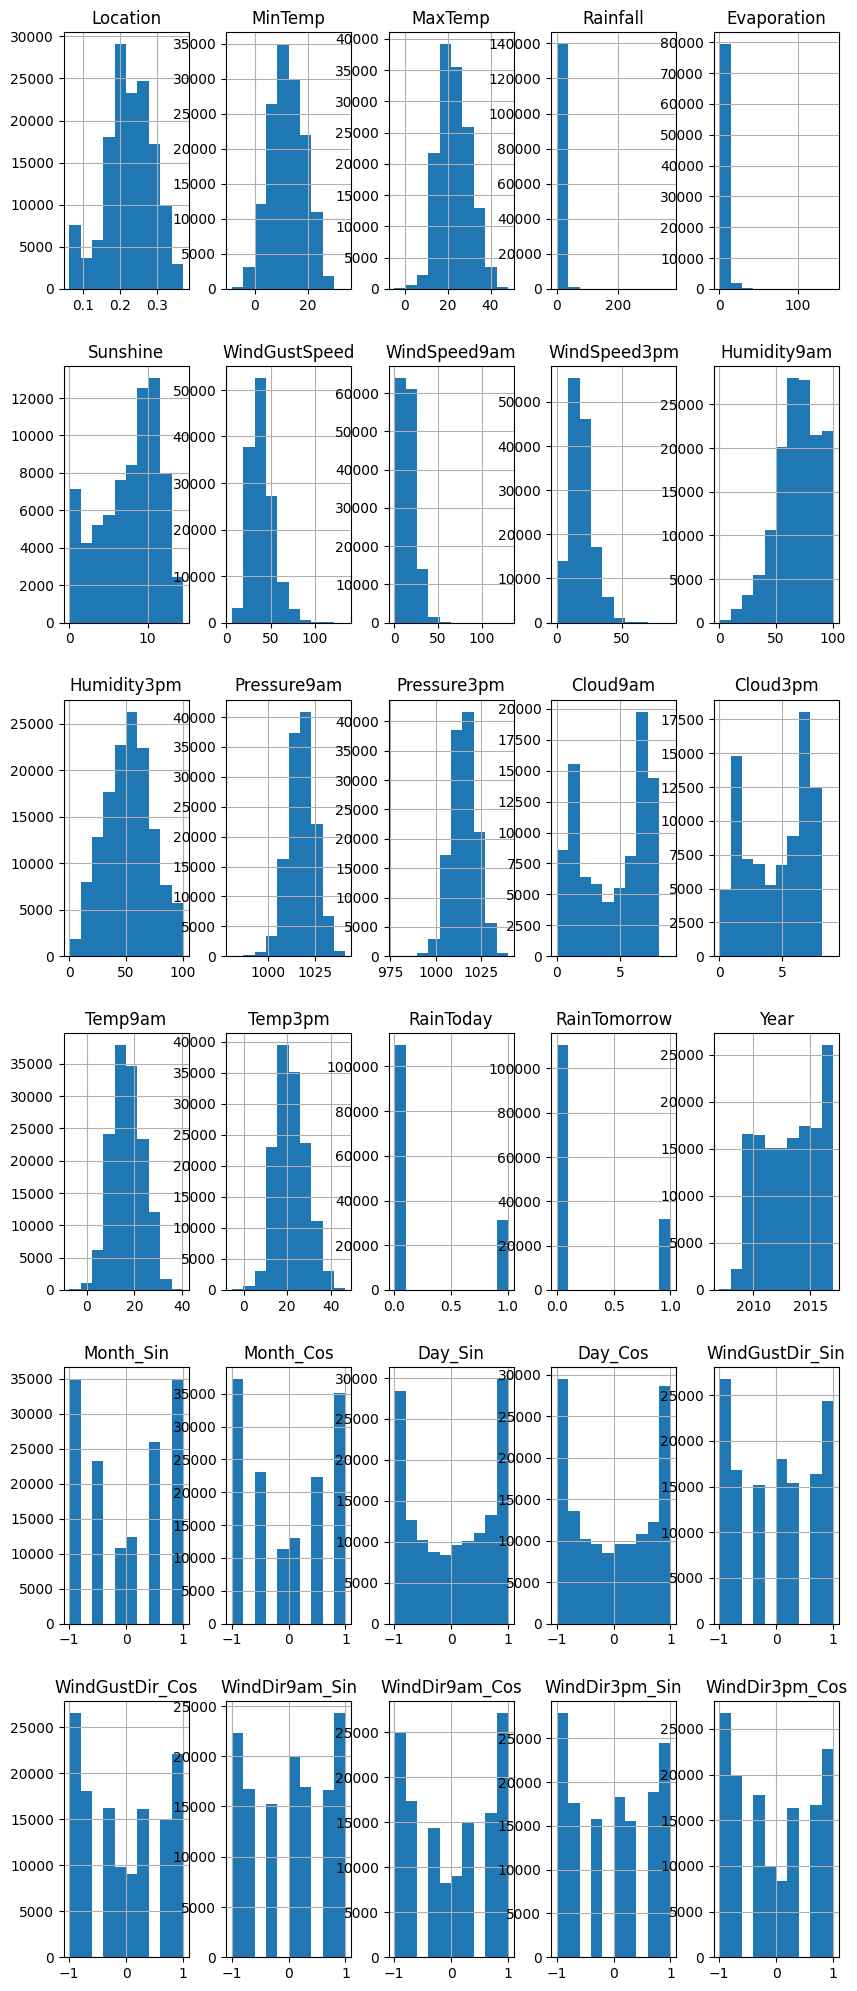

In [20]:
#Plotting the columns into histograms
axes = encoded_eda_dataset.hist(layout= (6,5), figsize=(10,25))
fig = axes.flatten()[0].get_figure()
plt.show()

The features with a normal distribution are: Location, MinTemp, MaxTemp, Temp3pm, Temp9am, WindGustSpeed, Humidity9am, Humidity3pm, Pressure9am, Pressure3pm, WindSpeed9am, WindSpeed3pm

The features with a U-shaped distribution are: Cloud3am, Cloud3pm, Month_Sin, Month_Cos, Day_Sin, Day_Cos, WindGustDir_Cos, WindGustDir_Sin, WindDir9am_Sin, WindDir9am_Cos, WindDir3pm_Sin, WindDir3pm_Cos

The features with a linear distribution are: RainToday, RainTomorrow, Rainfall, Evaporation

Sunshine almost looks like a skewed normal distribution, but the tail end has a lot of instances, and Year almost looks like a uniform distribution, but the lower end has fewer instances than the rest and the upper and has more instances than the rest. 

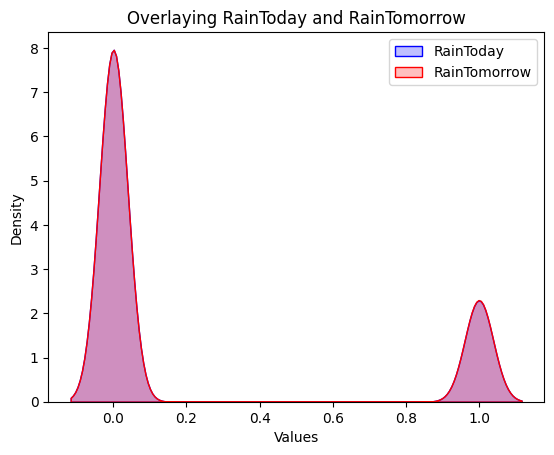

In [21]:
sns.kdeplot(encoded_eda_dataset['RainToday'], fill=True, color="blue", label="RainToday")
sns.kdeplot(encoded_eda_dataset['RainTomorrow'], fill=True, color="red", label="RainTomorrow")

plt.title("Overlaying RainToday and RainTomorrow")
plt.xlabel("Values")
plt.ylabel("Density")
plt.legend()
plt.show()

Interestingly the two columns RainToday and RainTomorrow are nearly identical in the kde graph. This is not necessarily a sign of any correlation as it could just mean that any given day has about a 20% chance of rain. 

<Axes: >

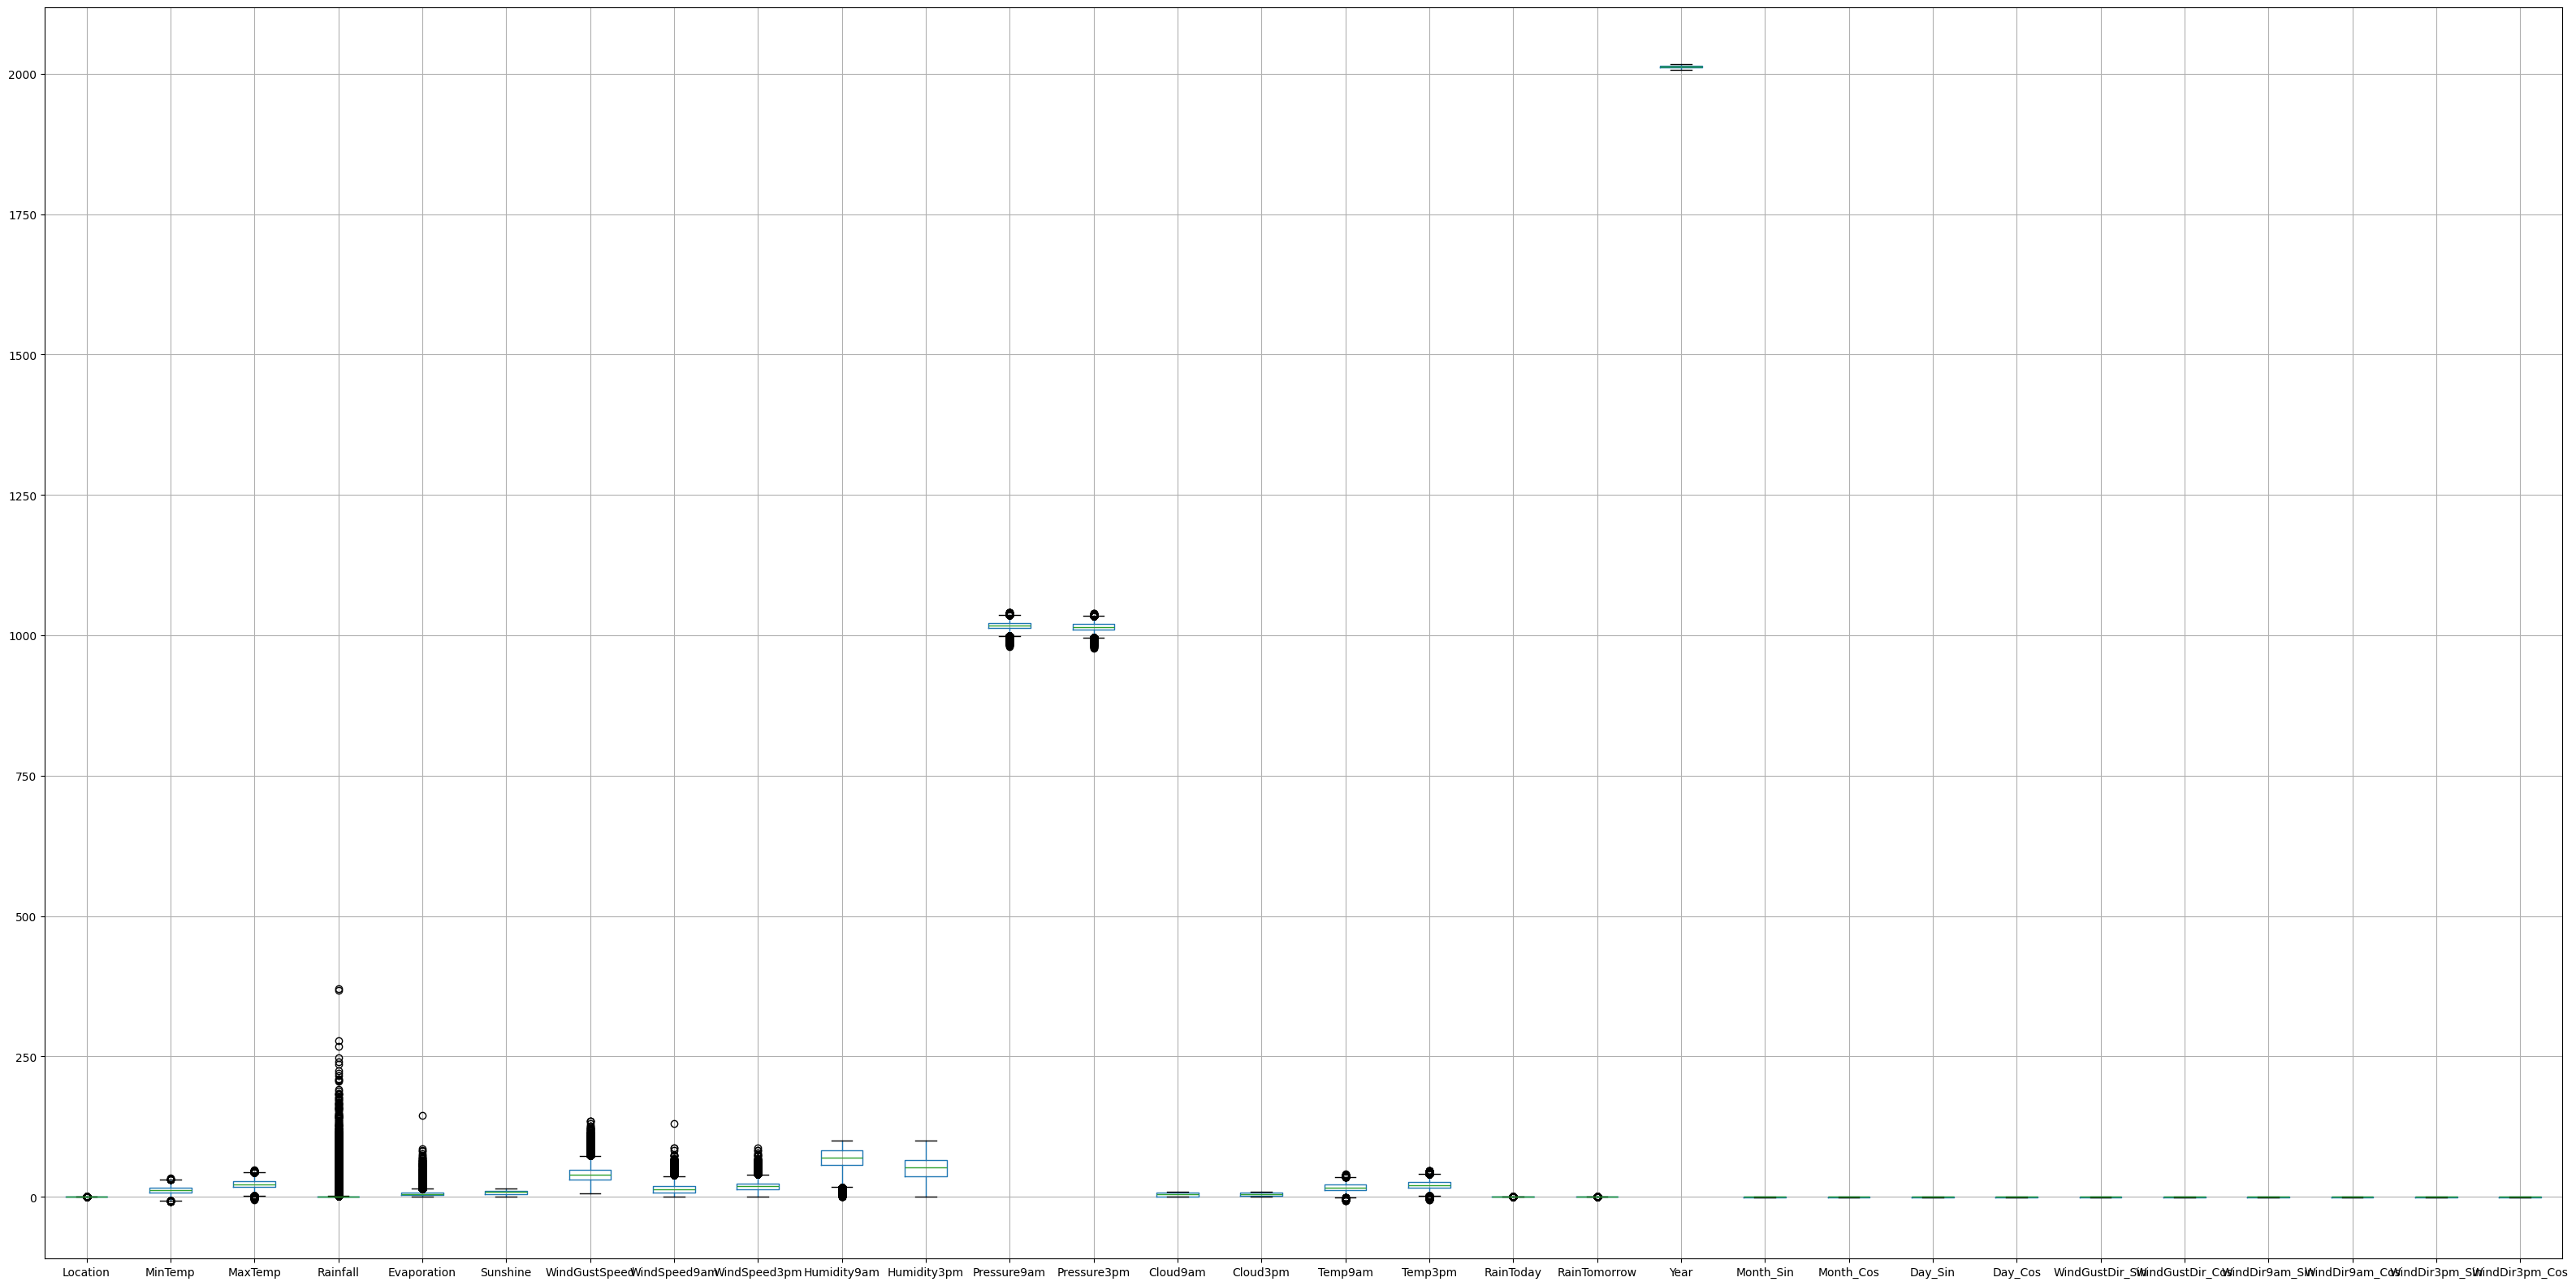

In [22]:
#Plotting the boxplots for the dataset
fig, ax = plt.subplots(1,1,figsize=(40, 20))
encoded_eda_dataset.boxplot()

There's not a lot to gain from this as there are too many features for the boxplot, so it makes sense to split it into several plots with similar sizes. 

<Axes: >

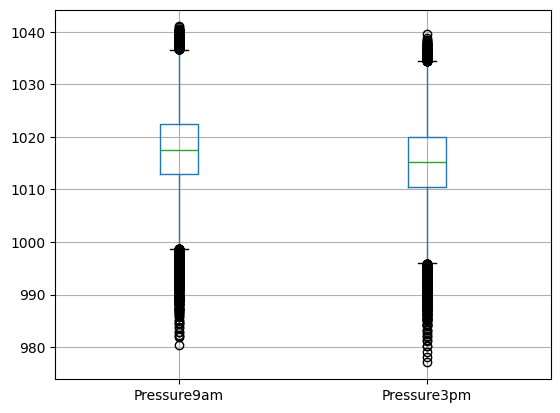

In [23]:
pressure_features = ['Pressure9am', 'Pressure3pm']
encoded_eda_dataset[pressure_features].boxplot()

The air pressure is slightly higher in the morning than during the day and this applies to the outliers as well. 

<Axes: >

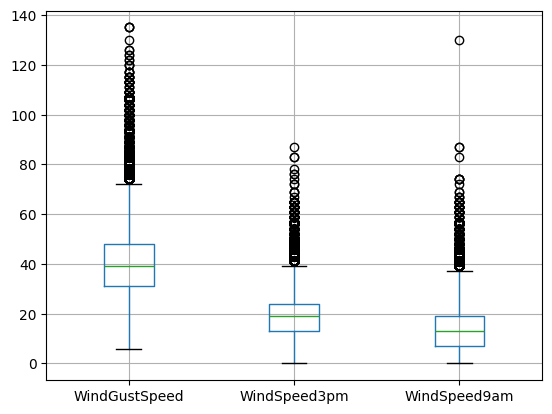

In [24]:
wind_speed_features = ['WindGustSpeed', 'WindSpeed3pm', 'WindSpeed9am']
encoded_eda_dataset[wind_speed_features].boxplot()

The wind guest speed is higher than the wind speeds as one would expect, but the wind speed is generally higher during the day than during the morning. This is the opposite pattern from what the air pressure showed. WindSpeed9am has a reading that is almost on the same level as the biggest WindGustSpeed outlier, so it might be worth considering for removal. 

<Axes: >

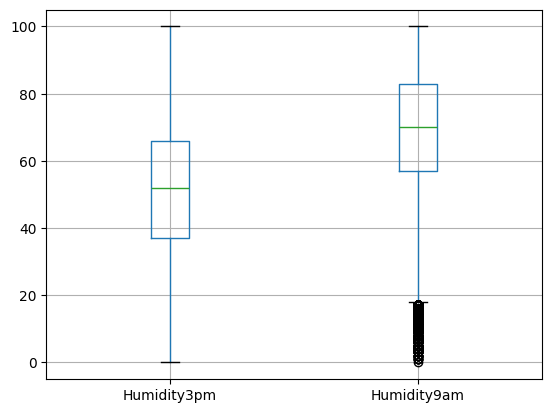

In [25]:
humidity_features = ['Humidity3pm', 'Humidity9am']
encoded_eda_dataset[humidity_features].boxplot()

The humidity is quite a bit higher during the morning than during the day. The humidity at 3pm is more or less evenly spread, although it's mostly concentrated during 

<Axes: >

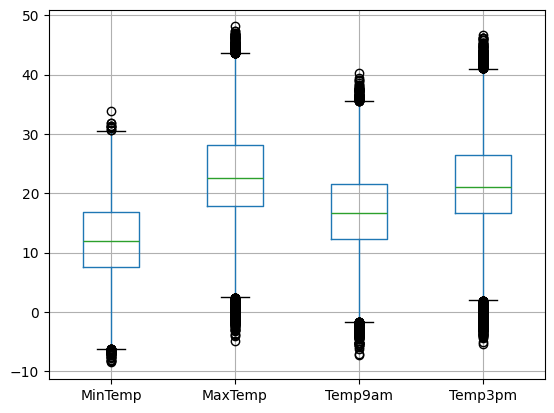

In [26]:
temp_features = ['MinTemp', 'MaxTemp', 'Temp9am', 'Temp3pm']
encoded_eda_dataset[temp_features].boxplot()

The temperature generally seems to vary by about 10 degrees during the day, but there seems to be more variation in the MaxTemp readings. The highest temperature happens somewhat close to 3pm, but the 9am temperature is quite a bit higher than the lowest temperature. 

<Axes: >

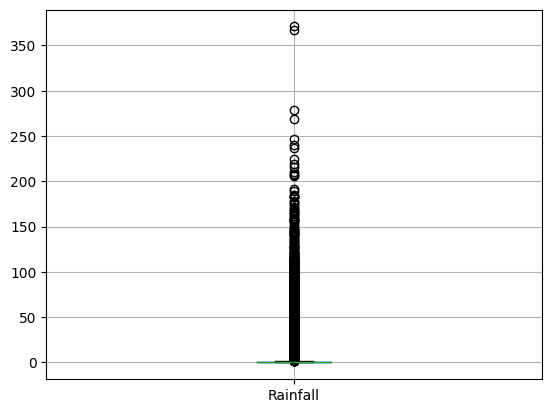

In [27]:
encoded_eda_dataset[['Rainfall']].boxplot()

There are a lot of outliers here. The reason for this could be that it only rains about 20% of days, so 3/4ths of the boxplot will be squished into this 0 rainfall count. The rainfall values exceeding 370 could be candidates for removal as they seem like big outliers.

<Axes: >

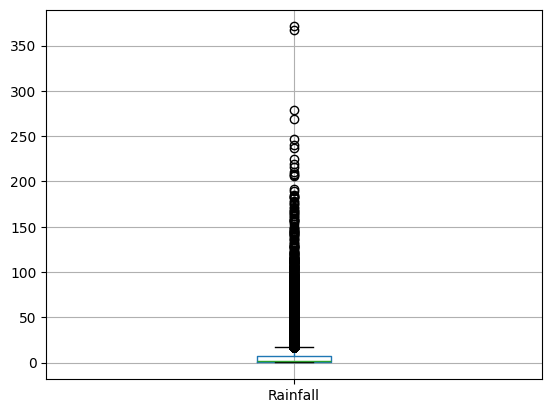

In [28]:
#Checking the rainfall without any zeroes
rainfall = encoded_eda_dataset[['Rainfall']]
rainfall_filtered = rainfall.loc[rainfall['Rainfall'] > 0]
rainfall_filtered.boxplot()

Rainfall is mostly concentrated from about one to 20mm of rain, with some outliers reaching all the way up to 370mm. 

<Axes: >

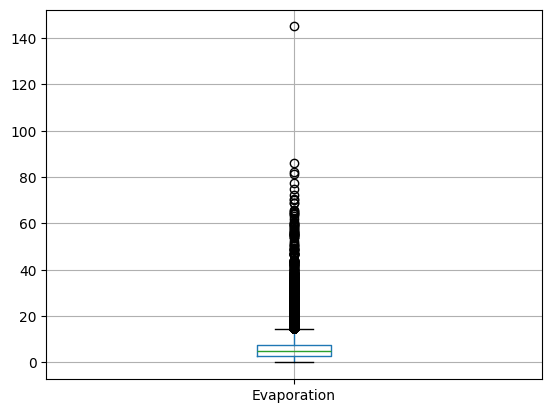

In [29]:
encoded_eda_dataset[['Evaporation']].boxplot()

Evaporation is mostly concentrated around 0-16mm/day, with one outlier reaching all the way up to around 140mm/day. This one could be considered for removal as it's nearly 60 mm/day higher than the second most count. 

<Axes: >

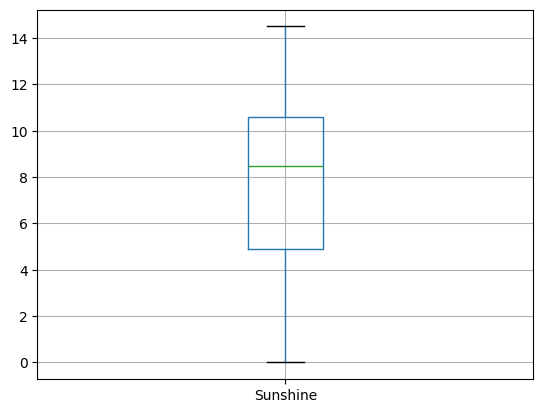

In [30]:
encoded_eda_dataset[['Sunshine']].boxplot()

Sunshine stretches from 0 hours all the way up to over 14 hours of sunshine a day. The average day will have somewhere between 5-10 hours of sunshine. 

<Axes: >

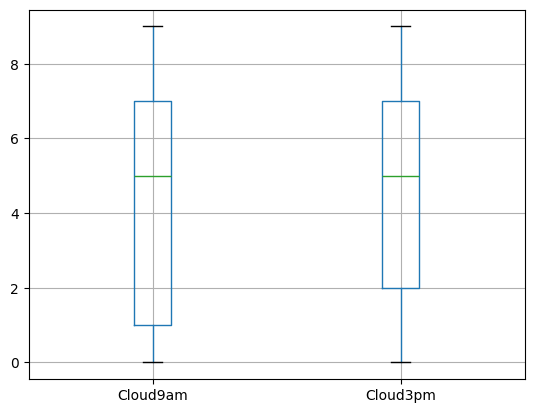

In [31]:
cloud_features = ['Cloud9am', 'Cloud3pm']
encoded_eda_dataset[cloud_features].boxplot()

The lower 50% of instances is more spread out at 9am than 3pm. There are more days with a cloud cover of 0-1 oktas at 9am than there are at 3pm. 

<Axes: >

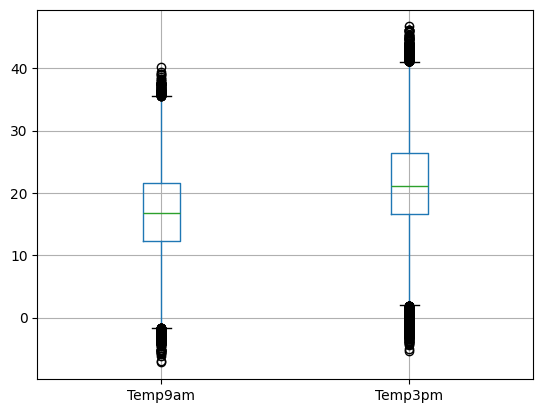

In [32]:
temp_features = ['Temp9am', 'Temp3pm']
encoded_eda_dataset[temp_features].boxplot()

The temperature is a few degrees higher during the day. The mean temperature at 3pm is about 21 degrees Celsius, while the mean temperature at 9am is about 16 degrees Celsius.

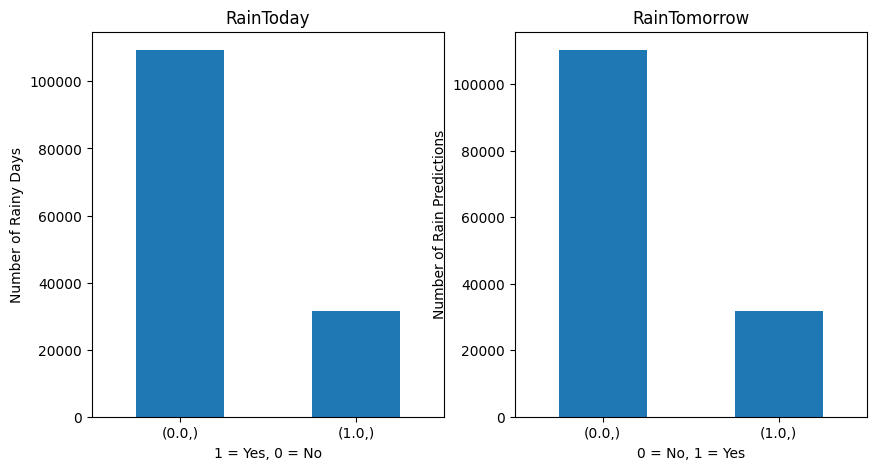

In [33]:
fig, axes = plt.subplots(1,2, figsize=(10,5))

encoded_eda_dataset[['RainToday']].value_counts().plot(kind="bar", ax=axes[0])

axes[0].set_title('RainToday')
axes[0].set_ylabel('Number of Rainy Days')
axes[0].set_xlabel('1 = Yes, 0 = No')
axes[0].tick_params(rotation=0)

encoded_eda_dataset[['RainTomorrow']].value_counts().plot(kind="bar", ax=axes[1])

axes[1].set_title('RainTomorrow')
axes[1].set_ylabel('Number of Rain Predictions')
axes[1].set_xlabel('0 = No, 1 = Yes')
axes[1].tick_params(rotation=0)

There are about 30000 instances of rain in both features and 110000 instances of no rain. 

<Axes: >

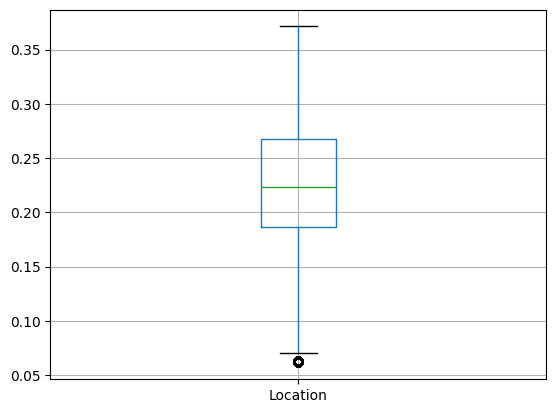

In [34]:
encoded_eda_dataset[['Location']].boxplot()

Location has been target encoded, and the probabilities vary from about 5% chance of rain tomorrow to about 35% chance of rain tomorrow. The mean seems to be around 22% which matches with RainTomorrow.  

array([[<Axes: title={'center': 'Date'}>]], dtype=object)

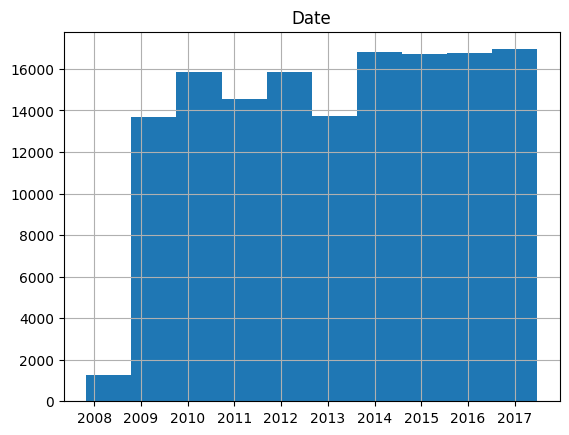

In [35]:
eda_dataset[['Date']].hist()

The date feature is close to uniform with 2008 being quite a bit lower than the others. This is most likely due to the records starting late in the year 2008. 


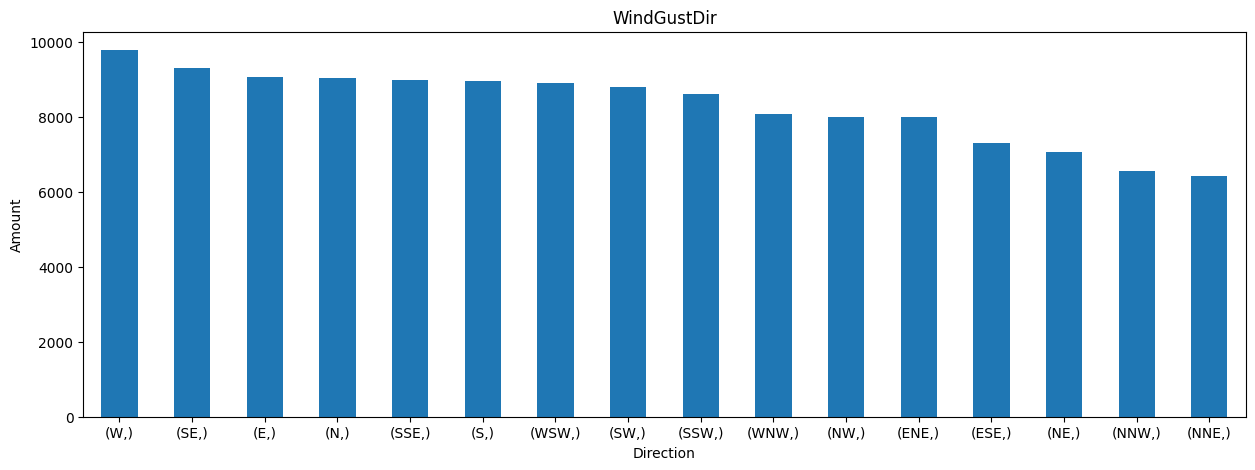

In [36]:
fig, axes = plt.subplots(1,1, figsize=(15,5))

eda_dataset[['WindGustDir']].value_counts().plot(kind="bar")

axes.set_title('WindGustDir')
axes.set_ylabel('Amount')
axes.set_xlabel('Direction')
axes.tick_params(rotation=0)

The most common wind gust direction is West and the least common is NNE. 

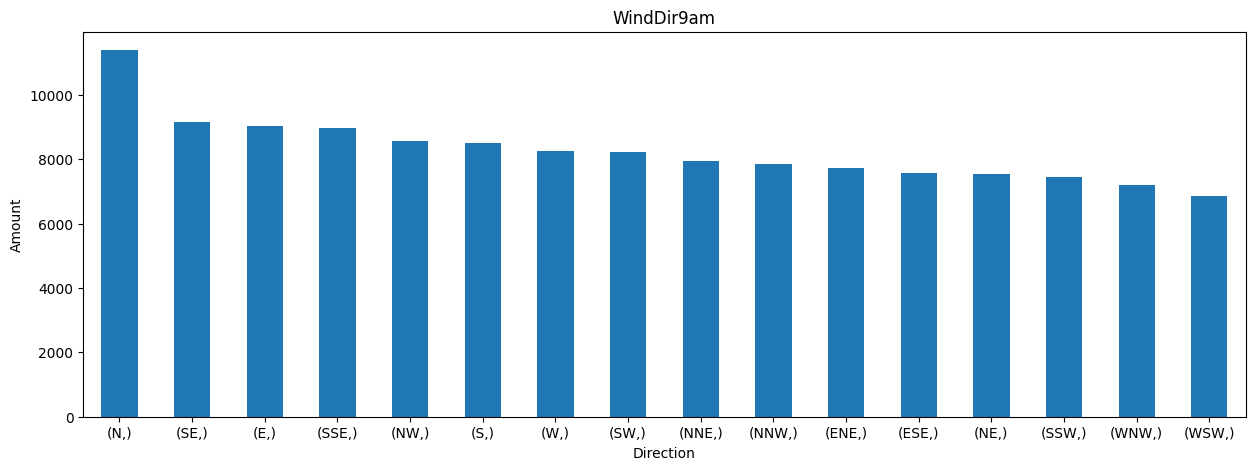

In [37]:
fig, axes = plt.subplots(1,1, figsize=(15,5))

eda_dataset[['WindDir9am']].value_counts().plot(kind="bar")

axes.set_title('WindDir9am')
axes.set_ylabel('Amount')
axes.set_xlabel('Direction')
axes.tick_params(rotation=0)

The most common wind direction at 9am is north. Interestingly it is much more common for the wind gust to be facing north, than the actual wind direction at 9am. 

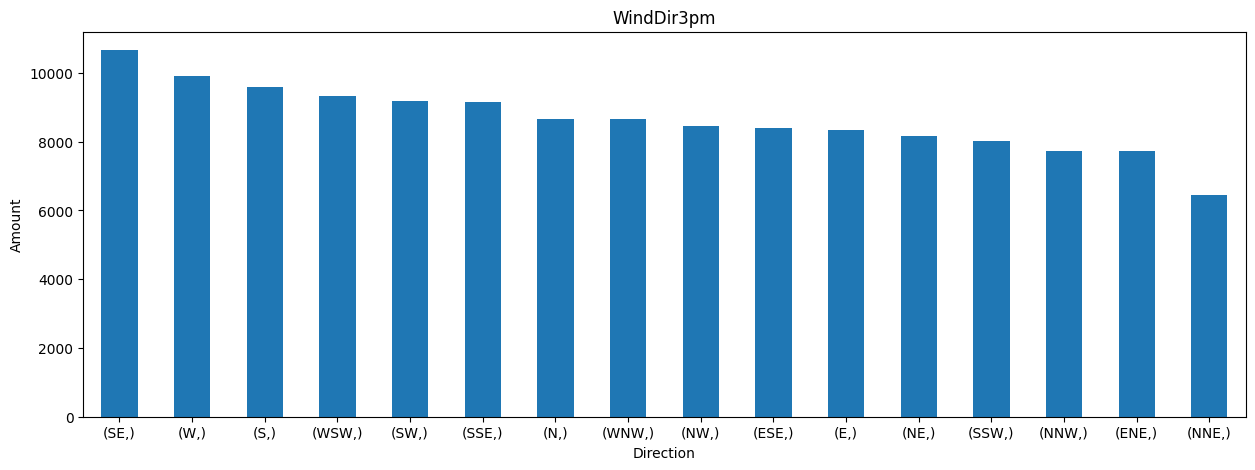

In [38]:
fig, axes = plt.subplots(1,1, figsize=(15,5))

eda_dataset[['WindDir3pm']].value_counts().plot(kind="bar")

axes.set_title('WindDir3pm')
axes.set_ylabel('Amount')
axes.set_xlabel('Direction')
axes.tick_params(rotation=0)

The wind direction at 3pm seems to be very similar to the wind gust direction, although the most common wind direction at 3pm is SE instead of W.  

### Multivariate Analysis

<Axes: >

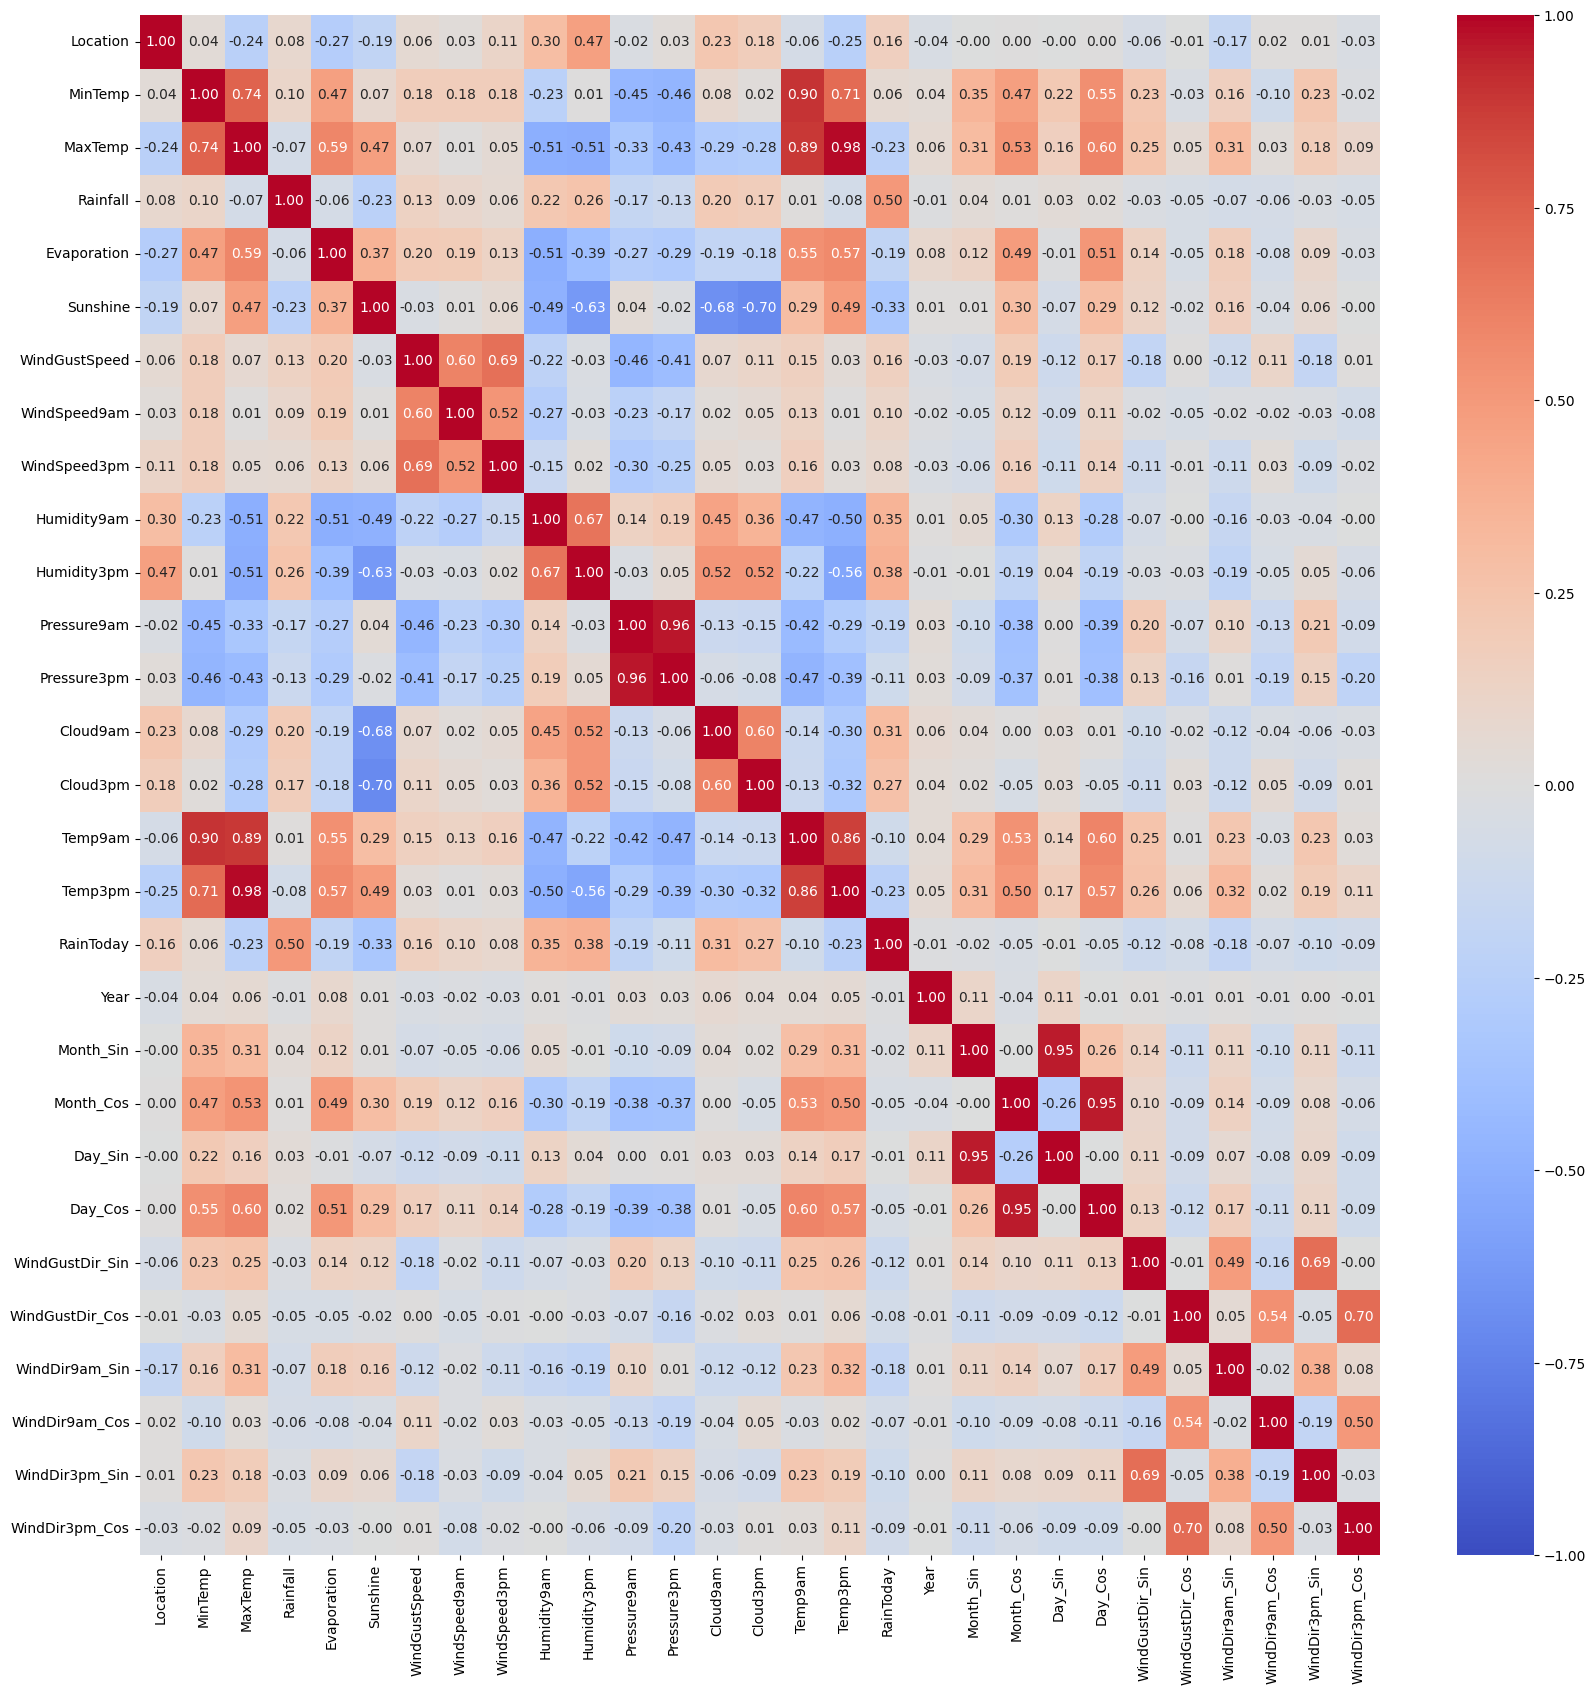

In [39]:
# Correlation heatmap.

# Computes the pairwise correlation between each feature.
correlation = encoded_eda_dataset.drop("RainTomorrow", axis=1).corr()

# Shows the correlation between the features in a heatmap.
plt.figure(figsize=(20, 20))
sns.heatmap(correlation, cmap='coolwarm', annot=True, fmt='.2f', vmin=-1, vmax=1)


#### Results
This dataset has features which have various levels of correlation between them. There are some obvious correlations such as the four temperature related features. In particular, the highest correlation between features is seen between MaxTemp and Temp3pm with a correlation of 0.98. Looking at other trends, there is at least some correlation between the 9 am and 3 pm observations for all features which has them. The second-highest correlation at 0.96, can be found between Pressure9am and Pressure3pm. Some of these correlations are so high that they warrant further investigation. Specifically, it is possible to remove the columns using pipelines. Removing one of the pressure columns, along with two of the temperature columns could improve the model.

There is also seasonal correlation between some of the weather features and the time features. Furthermore, there is a strong correlation between day and month. Due to the encoding this is indicated by the sin and cos being correlated to each other separately between the features. On the contrary, it is good that the year feature is not correlated to any other features. This means that the seasonality of the features have multiple years to be highlighted from. If this was not the case, one could have one or two years with differing climate statistics which skewed the models ability to predict future years' RainTomorrow values.

Perhaps surprising, RainToday and Rainfall only have 0.5 correlation. This is explored more later in this notebook.

#### Correlation in Relation to the Target
The following figure shows which features are most correlated with the target value. The features listed at the top and bottom are the most correlated with positive and negative correlation respectively.

<Axes: >

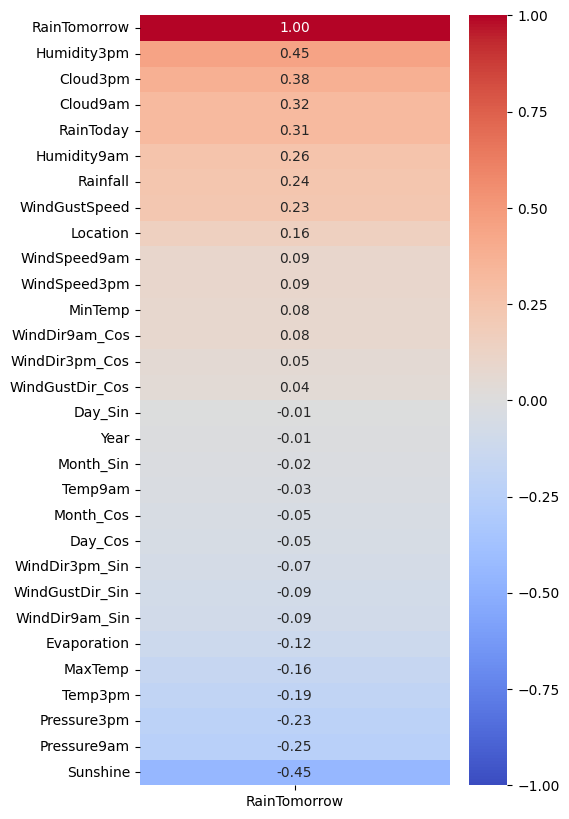

In [40]:
# Correlation heatmap part 2.

# Computes the pairwise correlation between each feature and the target value.
correlation = encoded_eda_dataset.corr()

# Shows the correlation between the target value and features ordered from the most positive correlation to the most negative correlation.
plt.figure(figsize=(5, 10))
sns.heatmap(correlation[['RainTomorrow']].sort_values(by=['RainTomorrow'],ascending=False), cmap='coolwarm', annot=True, fmt='.2f', vmin=-1, vmax=1)

Note: One can see that Pressure9am has slightly more correlation with the target value than Pressure3pm. If one of them is removed, it is indicated that it could be more sensible to remove Pressure3pm.

#### Scatterplot
Some of the most correlated features are investigated further. Additionally, two sets of uncorrelated features are looked at. These scatterplots show correlation if the datapoints follow a straight line with a rate of increase different from zero.

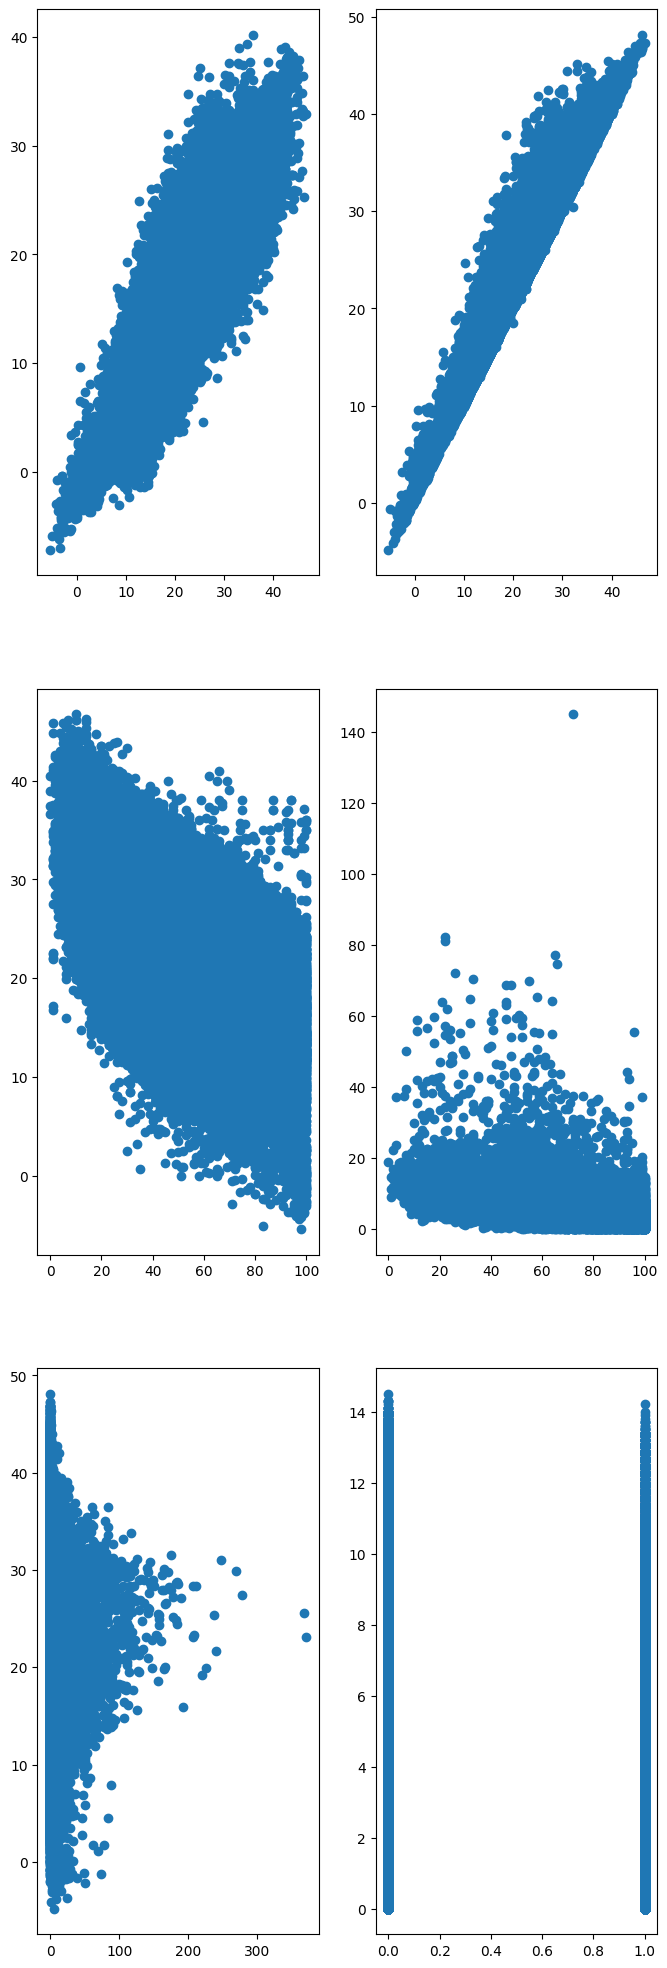

In [41]:
# Scatterplot.
fig, ax = plt.subplots(3, 2, figsize=(8,25))

ax[0, 0].scatter(encoded_eda_dataset['Temp3pm'], encoded_eda_dataset['Temp9am'])
ax[0, 1].scatter(encoded_eda_dataset['Temp3pm'], encoded_eda_dataset['MaxTemp'])
ax[1, 0].scatter(encoded_eda_dataset['Humidity3pm'], encoded_eda_dataset['Temp3pm'])
ax[1, 1].scatter(encoded_eda_dataset['Humidity9am'], encoded_eda_dataset['Evaporation'])
ax[2, 0].scatter(encoded_eda_dataset['Rainfall'], encoded_eda_dataset['MaxTemp'])
ax[2, 1].scatter(encoded_eda_dataset['RainToday'], encoded_eda_dataset['Sunshine'])

#### Results
The first two plots show that there is a strong positive correlation between the two timestamped temperatures and the temperature in the evening and the max temperature. These two are examples of some of the datasets largest correlations. This is no surprise as temperature will often vary based on season and location as well as time of day. Since these features have such high correlation, they could cause problems for the models. They could lead to an amplified importance and give less information to the model than the model perceives. For this reason, along with the processing required by the extra features, it could be positive to leave out some of the temperature columns. Since the target value doesn't care for which part of the day it is raining, seasonal aspects may be more important. Therefore, it could be beneficial to remove the features "Temp9am" and Temp3pm".

The third plot shows that there is a negative correlation between the evening's humidity and temperature. This means that the higher the humidity is, the lower the temperature is likely to be. This correlation is not as extreme as the previous examples and can be ignored and considered necessary to keep a diverse set of features.

A slight negative correlation can be found in the next plot. This can be seen by the absence of values near zero of humidity for the values near zero of evaporation. Furthermore, there are slightly more scattered points in the upper range of evaporation for the lower end of humidity. Other than that, there is very little correlation between the features and can therefore also be ignored.

The plot at the bottoms left shows that there is little correlation between rainfall and temperature. However, most values of the feature rainfall belongs in a range far below 100. This means that this graph highlights the outliers more than it covers general behavior. The most conclusive observations from this graph then, is that most of the outliers in rainfall occurs for days with a maximal temperature of about 16 to 32.

The last plot is difficult to read since the x-axis showing the RainToday feature is binary. Similarly to the last assignment, crosstables are used for binary data later in the notebook. For now, it is possible to detect that the features in the plot are not heavily correlated as there is a similar distribution of dots between the two binary values. How little correlation there is though, is not possible to tell from this plot alone.
#### Pairplot
For a larger overview of the correlation between features, a pairplot is provided to see most features' correlation. To keep the figure readable, both in terms of size of the overall pair plot and the readability of the individual graphs, the most discrete columns are excluded. This includes the target value. Additionally, where there is a value for the morning and afternoon, only the afternoon value is represented in the plot.

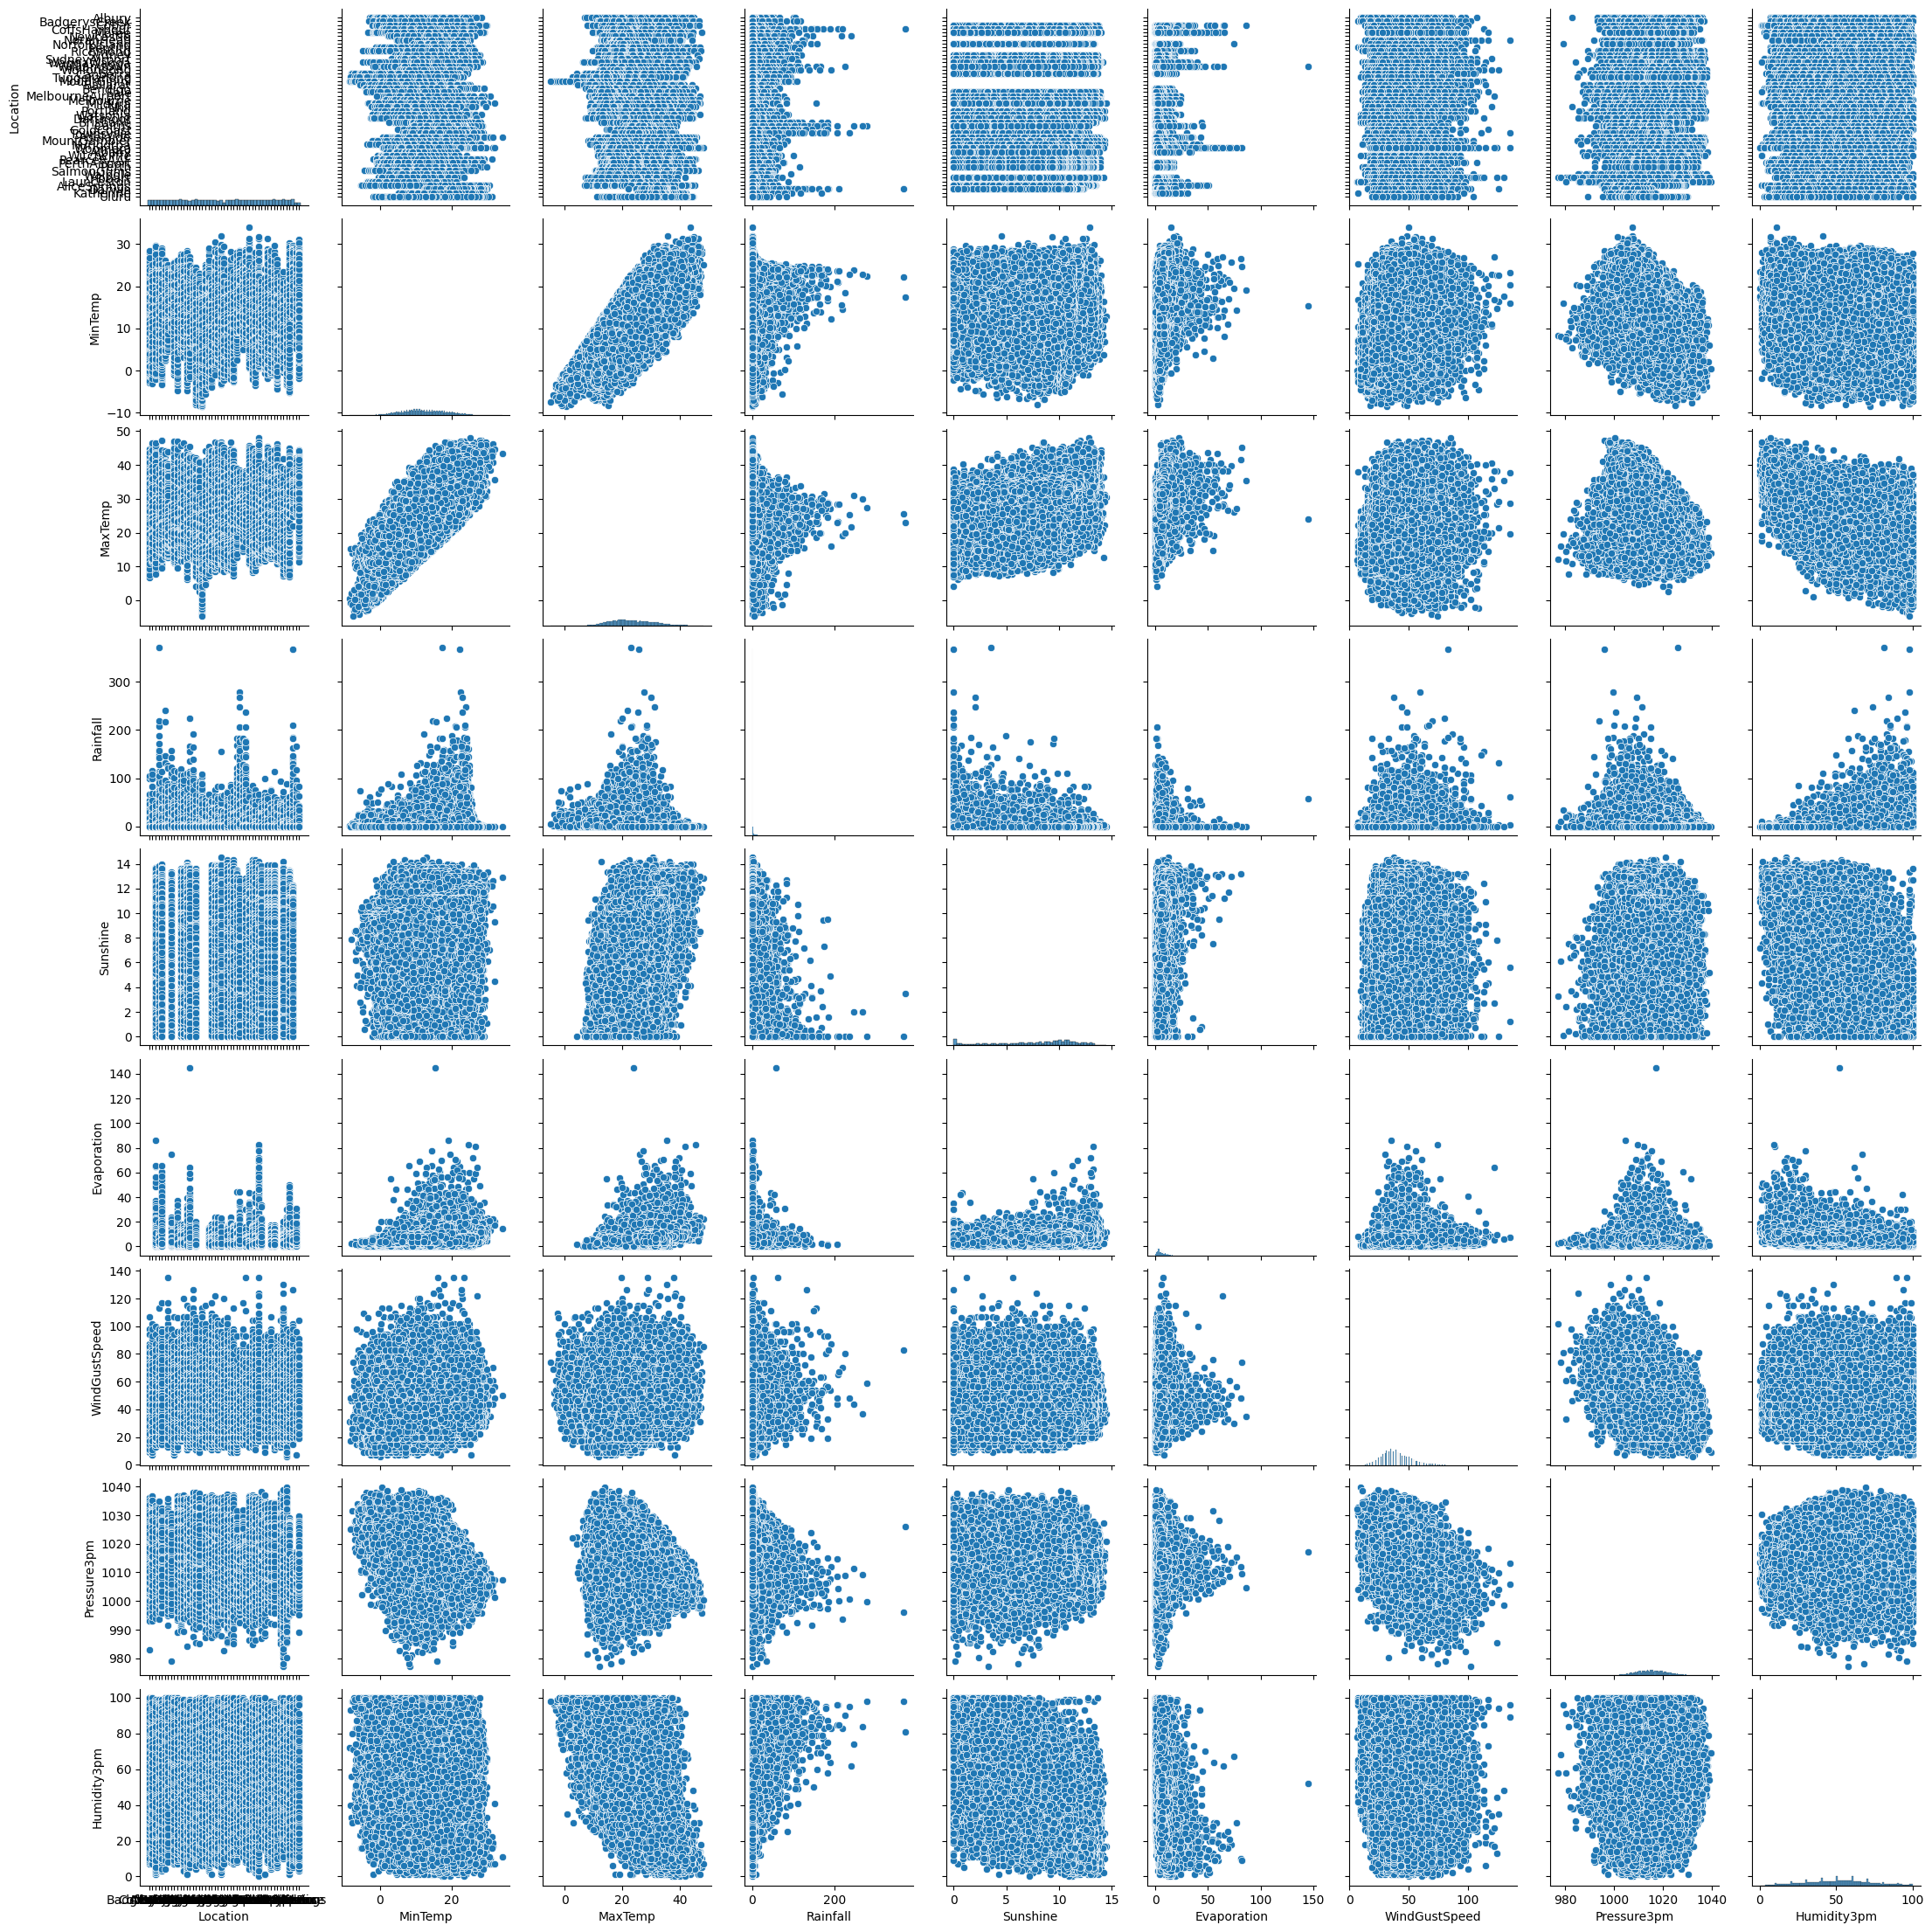

In [42]:
sns.pairplot(eda_dataset, vars=["Location", "MinTemp", "MaxTemp", "Rainfall", "Sunshine", "Evaporation", "WindGustSpeed", "Pressure3pm", "Humidity3pm"])

#### Results
One interesting observation which this plot uncovers, is the lack of multiple values for some locations. To the writers knowledge, it is not specified why this is. One can speculate various reasons, such that the weather stations did not have the relevant measuring instruments, or that the data was lost or erased before the making of the dataset. The relevant locations could have been investigated further in the missing values section to see which locations lack some features. A possibility would be to omit the locations which lack the most features, as their basis of data differs from the majority of features. This is not done due to time constraints. It is however worth noting that if the target encoding is applied to the data, there will be even more missing values for certain ranges of values. This is most likely because there isn't any locations which match the specific value after the encoding.  A more trivial observation is that rainfall varies based on the location. This is not surprising as Australia has a diverse climate where one would expect different amounts of rain for some of the climates. This observation comes with a similar caveat to previous plots that the outliers takes president in the plots with rainfall.

Most of the plots between features are scattered heavily. This means that there is only slight, if any, correlation between the features shown in the plot. The biggest exception to this, are the previously discussed temperature features.

#### Crosstables
Nine crosstables are provided as an alternative to scatterplots for discrete data with few possible values.
Seven of them, marked with a green color gradient, are between features. The other two are between a feature and the target value.

The first crosstable provided was the one which needed the most "tuning", or work, to get presentable. As such, four examples of the crosstable is provided, each subsequently improving on the last one.

In [43]:
# Optimize wind directions in the crosstables, making them more readable,
# A new "Compact_" wind direction is added to the dataset for the three features using wind directions.


# This is done by taking the value from the default wind direction and replacing their values them using simple regular expressions.
# The directions are compressed from the 16 default values to the four basic cardinal directions of north, east, south and west.
eda_dataset["Compact_WindGustDir"] = eda_dataset["WindGustDir"].replace(["N.*","E.*", "S.*", "W.*" ], ["North", "East", "South", "West"], regex=True)
eda_dataset["Compact_WindDir3pm"] = eda_dataset["WindDir3pm"].replace(["N.*","E.*", "S.*", "W.*" ], ["North", "East", "South", "West"], regex=True)
eda_dataset["Compact_WindDir9am"] = eda_dataset["WindDir9am"].replace(["N.*","E.*", "S.*", "W.*" ], ["North", "East", "South", "West"], regex=True)

<Axes: xlabel='RainTomorrow', ylabel='Sunshine'>

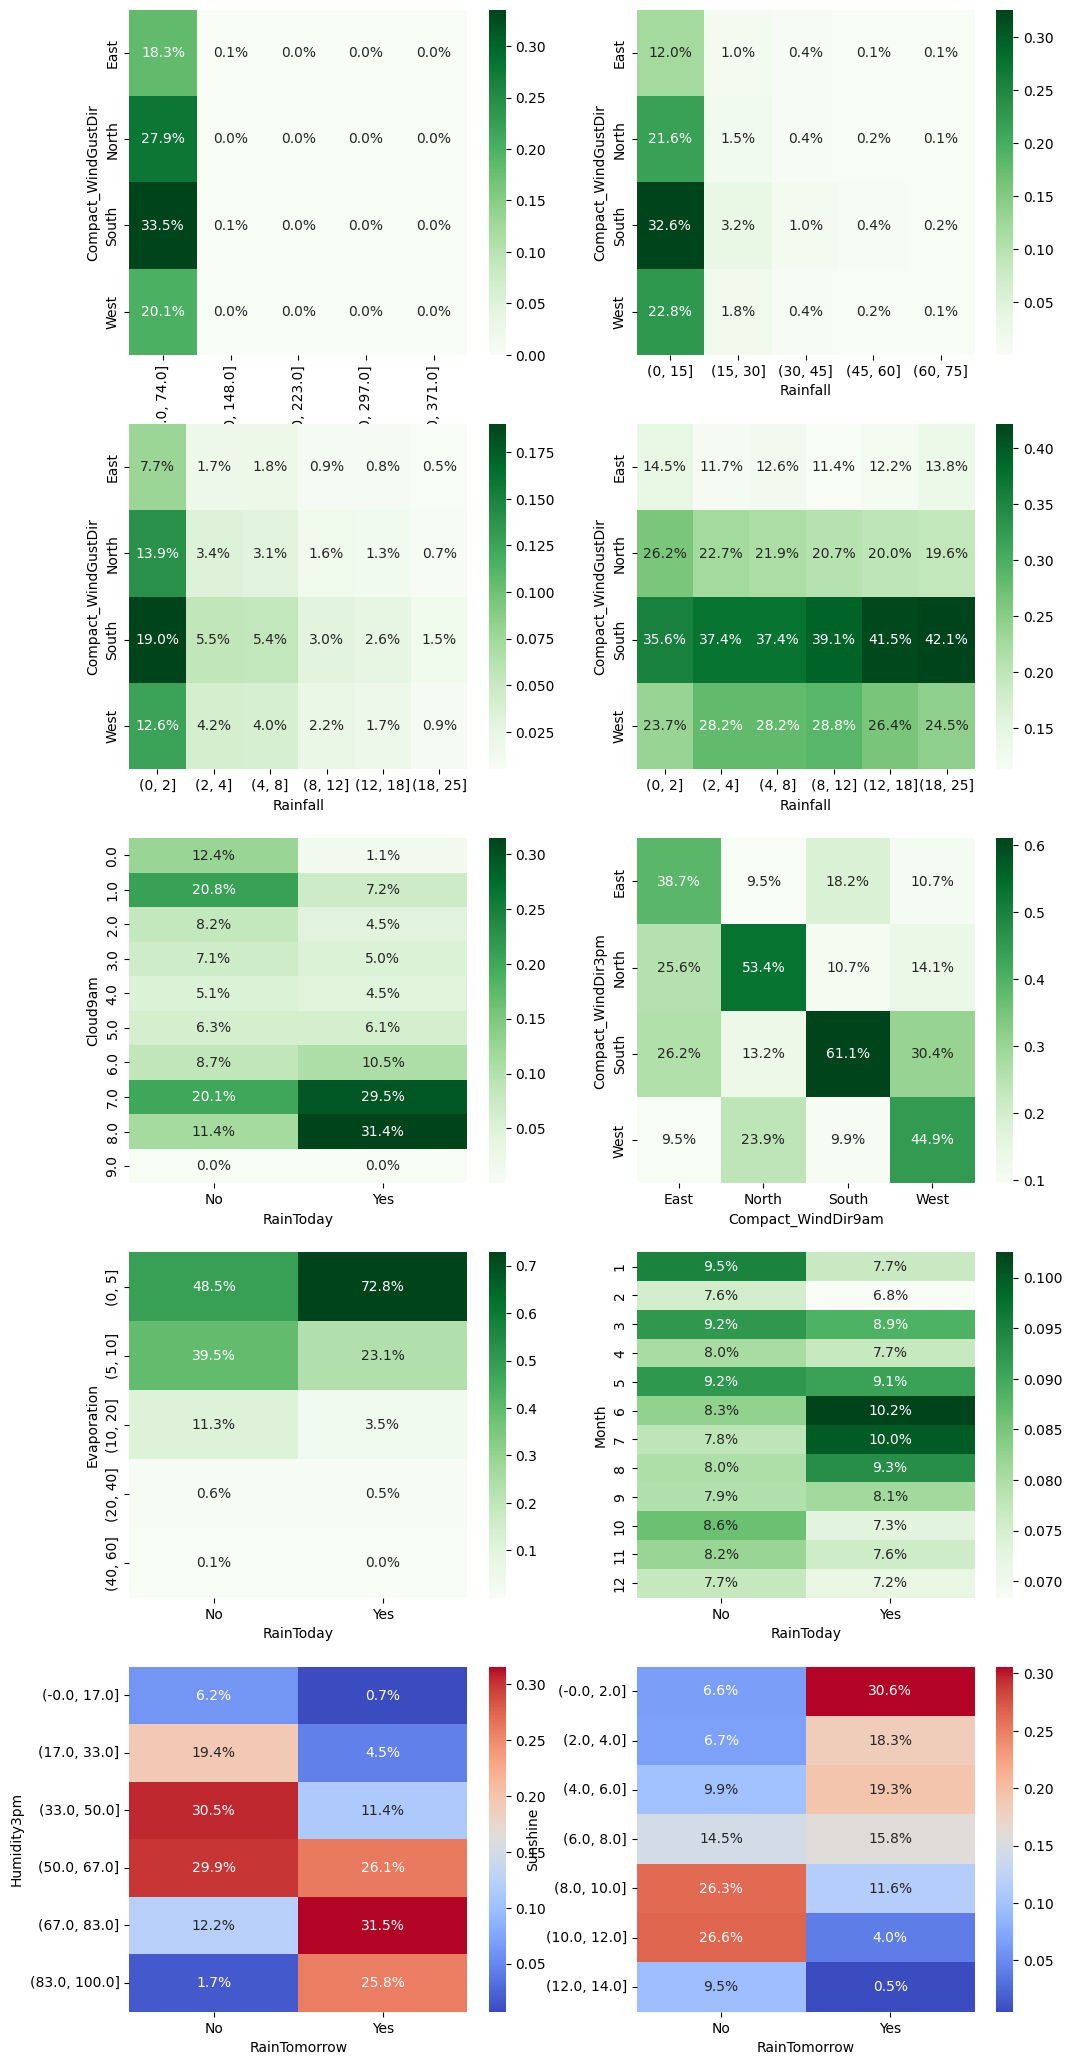

In [44]:
# Crosstables.
fig, ax = plt.subplots(5, 2, figsize=(12,26))


# Crosstables in between two features.
# Grouping/binning is used to make continuous features, or discrete features with many possible
# values more readable.
rainfall_grouped = pd.cut(eda_dataset["Rainfall"], 5, precision=0)
xtable1 = pd.crosstab(eda_dataset['Compact_WindGustDir'],
                      rainfall_grouped, normalize=True)
# If one looks at the first crosstable, it is clear rainfall higher than 74% are outliers.
# To get a better picture of the actual
bins = [0, 15, 30, 45, 60, 75]
rainfall_grouped = pd.cut(eda_dataset["Rainfall"], bins, precision=0)
xtable2 = pd.crosstab(eda_dataset['Compact_WindGustDir'],
                      rainfall_grouped, normalize=True)
# Further investigation reveals that it can be narrowed down even further.
# The bins are also unevenly distributed to get a better distribution of the percentages.
bins = [0, 2, 4, 8, 12, 18, 25]
rainfall_grouped = pd.cut(eda_dataset["Rainfall"], bins, precision=0)
xtable3 = pd.crosstab(eda_dataset['Compact_WindGustDir'],
                      rainfall_grouped, normalize=True)
# Lastly, the cells are normalized based on the column to better see the correlation
# between the features.
xtable4 = pd.crosstab(eda_dataset['Compact_WindGustDir'],
                      rainfall_grouped, normalize="columns")


xtable5 = pd.crosstab(eda_dataset['Cloud9am'],
                      eda_dataset['RainToday'], normalize="columns")

xtable6 = pd.crosstab(eda_dataset['Compact_WindDir3pm'],
                      eda_dataset['Compact_WindDir9am'], normalize="columns")

# For the same reason as rainfall, this needs to be grouped into smaller groups
# manually, near zero.
bins = [0, 5, 10, 20, 40, 60]
evaporationGrouped = pd.cut(eda_dataset["Evaporation"], bins, precision=0)
xtable7 = pd.crosstab(evaporationGrouped,
                      eda_dataset['RainToday'], normalize="columns")

xtable8 = pd.crosstab(eda_dataset['Month'],
                      eda_dataset['RainToday'], normalize="columns")

# Crosstables between features and target value.
# More binning of continuous features:
humidityGrouped = pd.cut(eda_dataset["Humidity3pm"], 6, precision=0)
xtable9 = pd.crosstab(humidityGrouped,
                      eda_dataset['RainTomorrow'], normalize="columns")

sunshineGrouped = pd.cut(eda_dataset["Sunshine"], 7, precision=0)
xtable10 = pd.crosstab(sunshineGrouped,
                      eda_dataset['RainTomorrow'], normalize="columns")


# Show the crosstables as heatmaps.
# Tables between features.
sns.heatmap(xtable1, cmap='Greens', annot=True, fmt='.1%', ax=ax[0, 0])
sns.heatmap(xtable2, cmap='Greens', annot=True, fmt='.1%', ax=ax[0, 1])
sns.heatmap(xtable3, cmap='Greens', annot=True, fmt='.1%', ax=ax[1, 0])
sns.heatmap(xtable4, cmap='Greens', annot=True, fmt='.1%', ax=ax[1, 1])
sns.heatmap(xtable5, cmap='Greens', annot=True, fmt='.1%', ax=ax[2, 0])
sns.heatmap(xtable6, cmap='Greens', annot=True, fmt='.1%', ax=ax[2, 1])
sns.heatmap(xtable7, cmap='Greens', annot=True, fmt='.1%', ax=ax[3, 0])
sns.heatmap(xtable8, cmap='Greens', annot=True, fmt='.1%', ax=ax[3, 1])

# Tables between a feature and the target.
sns.heatmap(xtable9, cmap='coolwarm', annot=True, fmt='.1%', ax=ax[4, 0])
sns.heatmap(xtable10, cmap='coolwarm', annot=True, fmt='.1%', ax=ax[4, 1])

#### Results
The results are given as bullet points which lists interesting observations from the cross tables.
- While research suggests that Australia traditionally sees more rain in the summer, with peaks in January, the data shows that the months with the most rainy days were actually in the winter for the relevant time period.
- The most common wind gust direction is south. The higher the rainfall, the more likely it is that the wind gust direction is south.
- Cloud9am have a high correlation to RainToday. This means that the amount of clouds on a given day is correlated with the chance of there being rain that day. A cloud level of 7 or 8 is the most common for days with rain. Lastly, the cloud-rain crosstable shows that there are very few entries with cloud level 9.
- About 50% percent of days have an unchanged wind direction at the two observation times of 9am and 3pm. These two features are therefore correlated at a medium rate.
- If a wind direction is measured at 9am, the most likely wind direction for 3pm is always the same direction. However, it is only for the directions of north and south that it is most likely for the 3pm wind direction to be the same as the 9pm measurement.
- There are some outliers for the evaporation feature. Most observations have a value below 20. Evaporation has some correlation to the RainToday feature as if it rained a given day, it is more likely that the evaporation was low.
- Rain is correlated with month. The months which have the most days with rain is in the winter. If it rained on a given day, it is most likely to be June, followed closely by July.
- If it is going to rain tomorrow, it is most likely that the humidity at 3pm is higher.
- Sunshine has a relatively strong correlation to the target value RainTomorrow. A plurality of days with rain has 0-2 levels of sunshine, while most have between 0-6.

<Axes: xlabel='Month', ylabel='DayOfYear'>

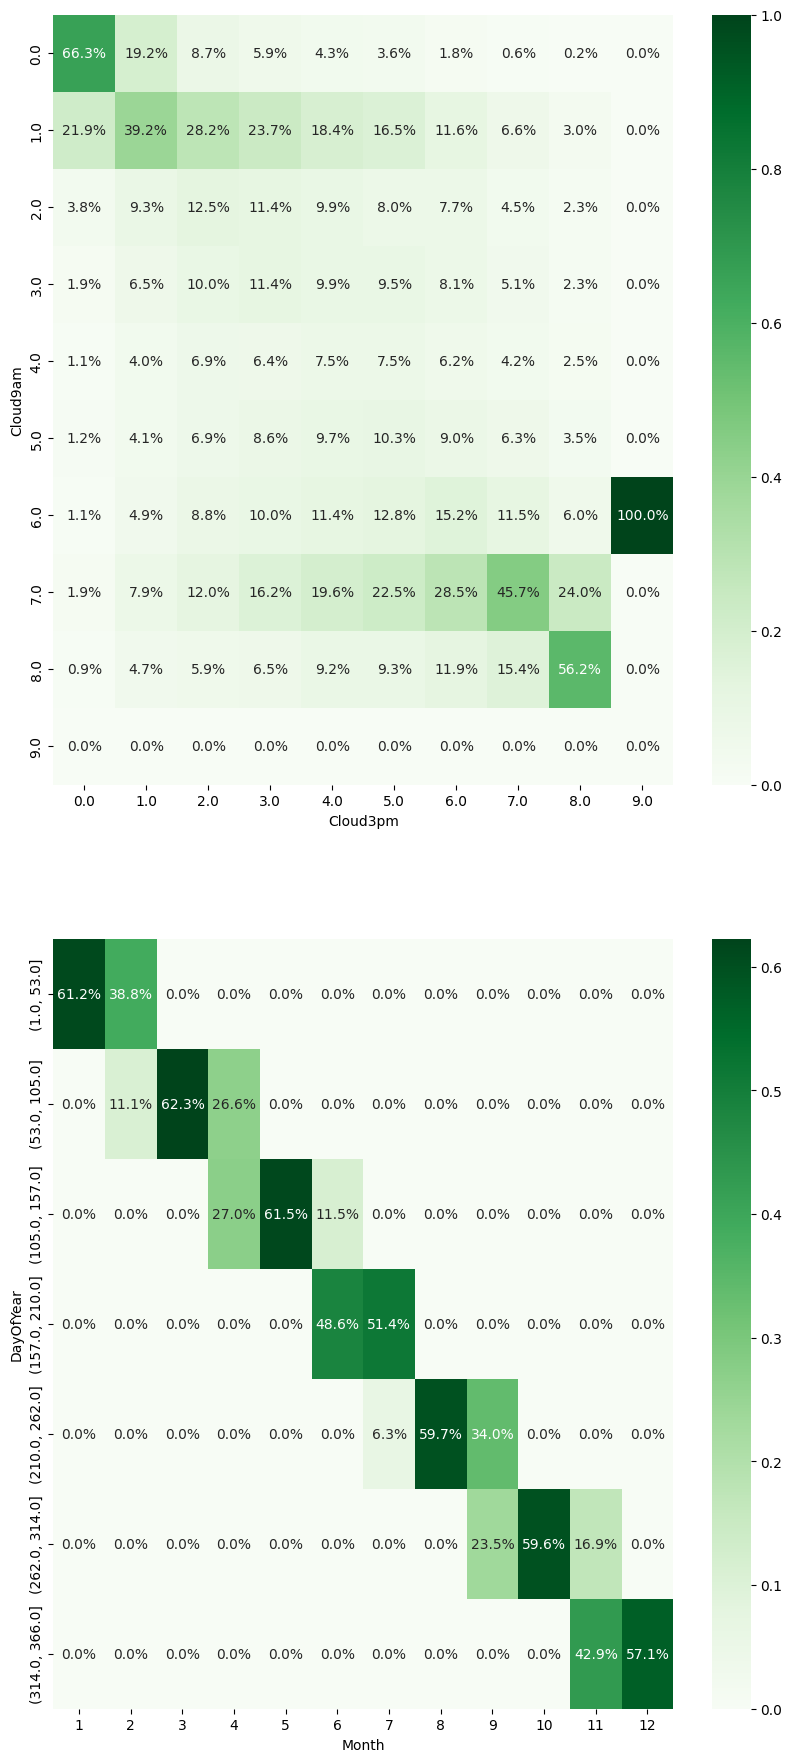

In [45]:
# Larger crosstables
# Both are between two features.

fig, ax = plt.subplots(2, 1, figsize=(10,22))

xtable1 = pd.crosstab(eda_dataset['Cloud9am'],
                      eda_dataset['Cloud3pm'], normalize="columns")
# There are a lot of days in a year, so they need to be grouped into smaller bins for
# the table to be readable.

days_grouped = pd.cut(eda_dataset["DayOfYear"], 7, precision=0)

xtable2 = pd.crosstab(days_grouped,
                      eda_dataset["Month"], normalize="index")


sns.heatmap(xtable1, cmap='Greens', annot=True, fmt='.1%', ax=ax[0])
sns.heatmap(xtable2, cmap='Greens', annot=True, fmt='.1%', ax=ax[1])

#### Results
The first table shows that there is some correlation between the cloud levels at 9AM and 3PM. The two features are most correlated at the extremes. This makes sense as if the clouds only partially cover the sky, the degree of coverage can more easily change throughout the day. The combination of the extremes and the partial coverage range makes the features only moderaltely correlated.

The second table shows heavy correlation between day of year and month. This is of course not surprising but highlights two of the most correlated features in the dataset. The features actually gives the same information, just with different time intervals. However, this may not affect the models performance as the time and seasonal aspect of the dataset is important to determine the target value. Lastly it is worth noting that if the bins for days would match the amount of days in each month, the table would show full correlation between the features.

### Location
Location doesn't really fit into a crosstable, as even though it is discrete, it has 49 unique values. One plot is still given to show that the amount of days with rain varies based on the location. This can already be inferred from the fact that the correlation between location and the target value is different from zero. A similar statistic, how much rain each location gets, is also shown in the pairplot by seeing the cell for location and rainfall.

<Axes: xlabel='count', ylabel='Location'>

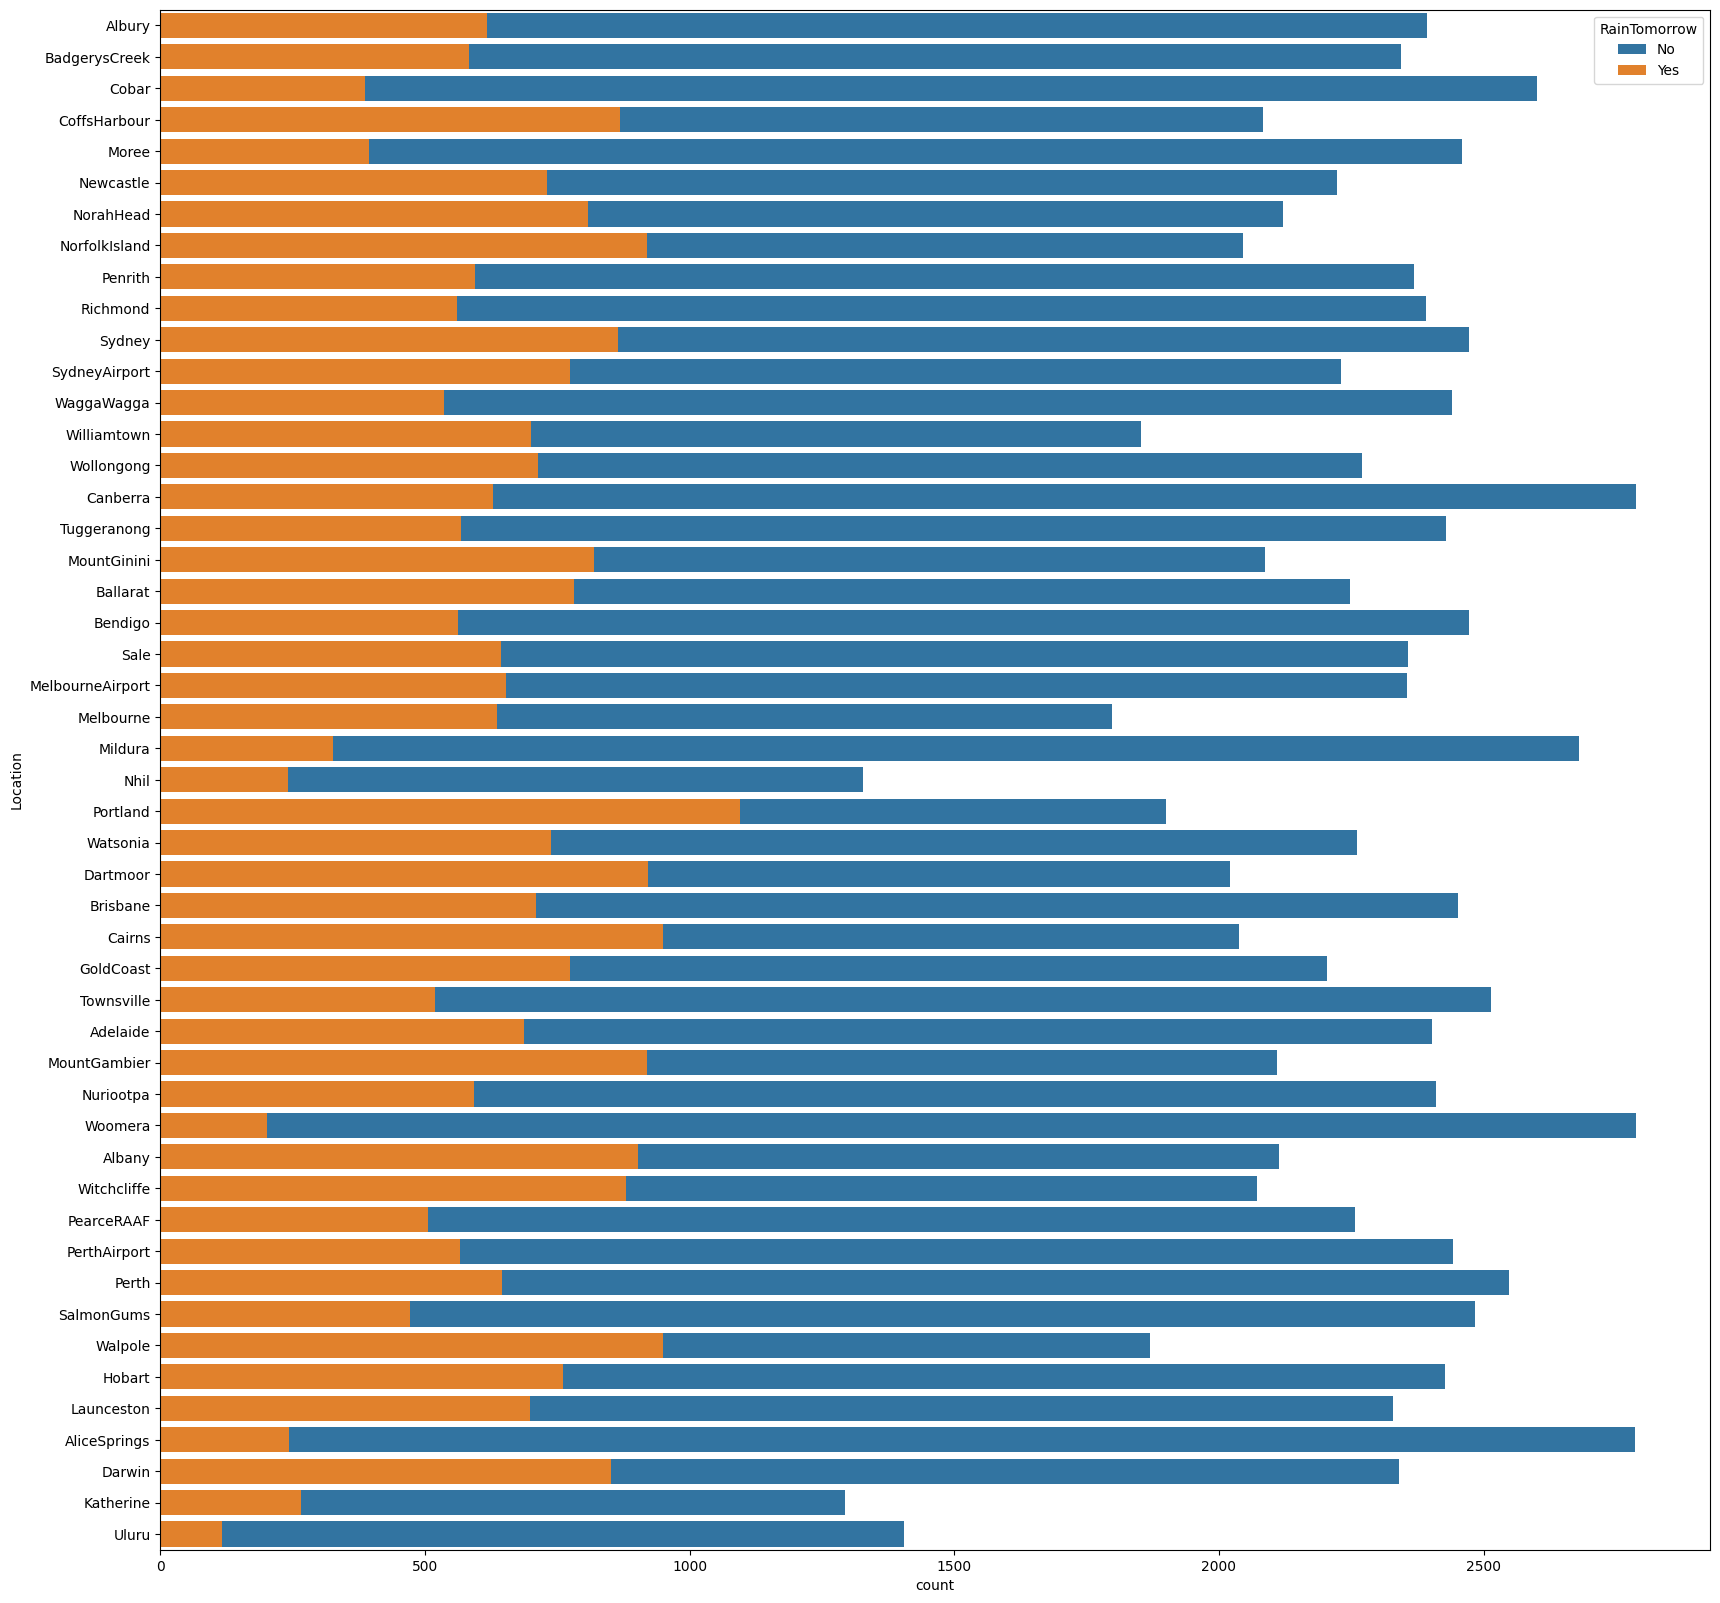

In [56]:
plt.figure(figsize=(20, 20))
sns.countplot(eda_dataset, y="Location", hue="RainTomorrow", dodge=False )

#### Results
It is worth noting that when interpreting these results, as mentioned in the univariate analysis chapter, that some locations have fewer entries in total than other locations. This can be seen from the graph as well. Overall there are some areas which barely sees days with rain, and there are other areas, like Portland, which has more than half as many days with rain compared to without. The graph also shows that some locations which are close to each other share the probability of the target value. This doesn't translate well in the encoding of the data. An ideal way of encoding would be to retain the positional properties of each location. This could be done by using x and y coordinates, but it is out of scope for this assignment.

### Time Series Analysis
The primary benefit of the time series analysis is to see periodic behavior and evolving trends. It is also a good way of showing the seasonality of some of the features, even though it might be obvious. This will then show the reason for the cyclic encoding.

In this dataset it is most relevant to see how rainfall evolves over time. While it is not the target value, it is a continuous way of showing rain over time. And, since most of the observations include days following directly from one another, it will in practise often show similar trends to the target value, but in a continuous manner. Other seasonal features are also explored.

<Axes: xlabel='Month', ylabel='Rainfall'>

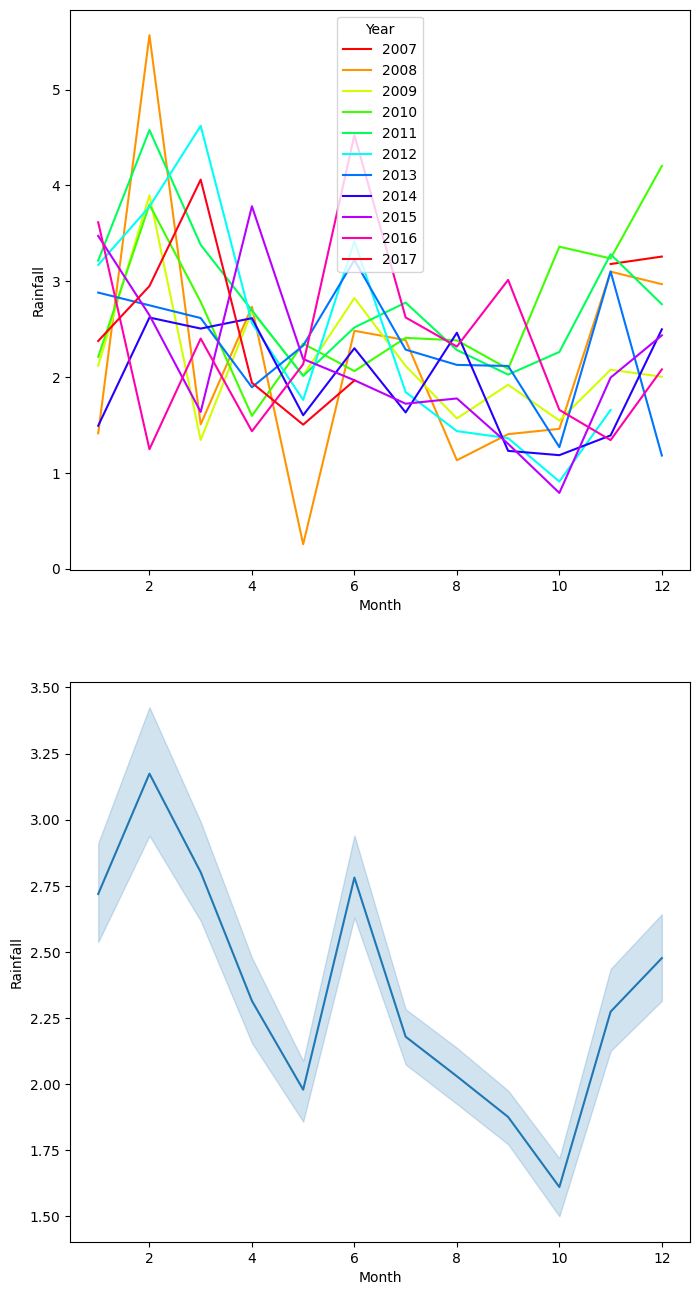

In [47]:
# Lineplot for rainfall.
fig, ax = plt.subplots(2, 1, figsize=(8,16))
x = "Month"
y = "Rainfall"
# Separate years
sns.lineplot(eda_dataset, x=x, y=y, hue="Year", palette="hsv", errorbar=None, legend="full", ax=ax[0])

# All years
sns.lineplot(eda_dataset, x=x, y=y, ax=ax[1])

#### Results
The first graph is noisy and difficult to read. Some general trends can be observed, but the most useful observation from the graph is that the rainfall varies depending on the year. This means that the year itself is not a useful metric for the model. Instead, the years are simply there to provide more data to find the seasonal aspects of the other features. The general trend in rainfall can be observed from the second graph which shows an increase in rainfall in the summer and winter months. February has the most rainfall according to the graph. It is worth noting, as is done previously, that this is rainfall and not the target value of days where it rains.

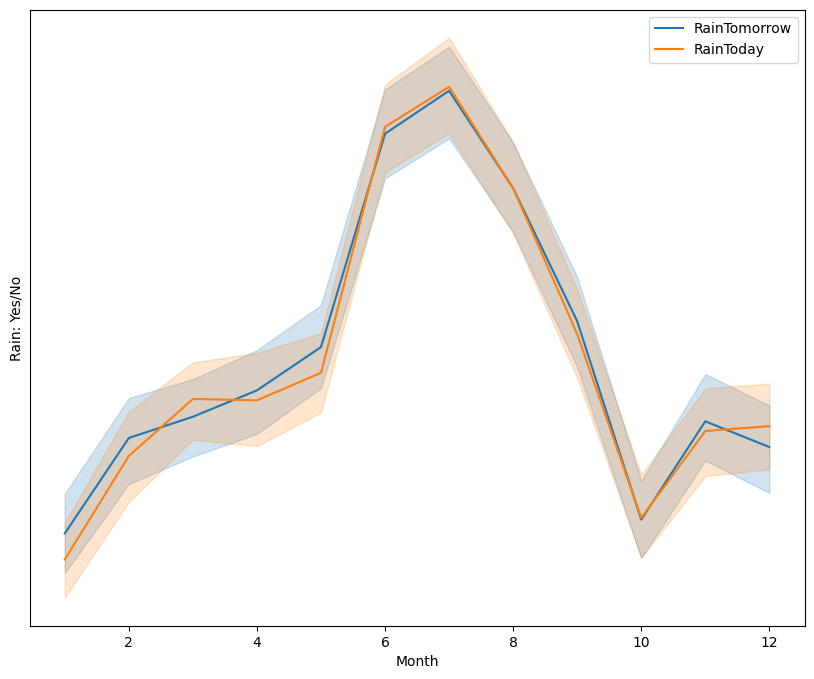

In [48]:
# Lineplot for RainTomorrow (target value).
fig, ax = plt.subplots(1, 1, figsize=(10,8))

x = "Month"
y = "RainTomorrow"
sns.lineplot(eda_dataset, x=x, y=y, ax=ax, label="RainTomorrow")


y = "RainToday"
sns.lineplot(eda_dataset, x=x, y=y, ax=ax, label="RainToday")

# Set common label of y-axes.
ax.set(ylabel = "Rain: Yes/No")
# Gives the months with the most days with rain a higher position on the graph, rather than lower.
ax.invert_yaxis()


#### Results
This graph shows that the RainToday and RainTomorrow follows each other as one can expect. Ideally, if every day has full observations given in the dataset, every month would have the same amount of RainToday and RainTomorrow except for the first and last day of the month.

The more important observation is that the amount of days where it rains peaks in winter. In particular, the month with the most days with rain is July according to this plot. The graph shows a large discrepancy between the amount of rainfall and amount of days with rain for the summer months. While according to the previous graph, February sees the most rainfall, it also sees far fewer days with rainfall than fall and summer months.

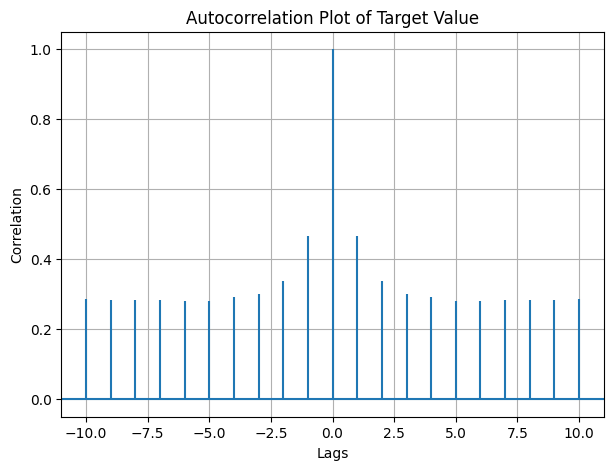

In [49]:
plt.figure(figsize=(7,5))
plt.acorr(encoded_eda_dataset['RainTomorrow'], maxlags=10)
plt.xlabel('Lags')
plt.ylabel('Correlation')
plt.title('Autocorrelation Plot of Target Value')
plt.grid(True)

This plot shows that if RainTomorrow is true for one day, it is more likely to be true for the following and previous day than a random day. This means that if it rains, it will often rain more than just that one day alone. The plot indirectly indicates correlation between the RainToday feature and the RainTomorrow target value. Note that, while the data is ordered by the date of the observations, it is only ordered by date for a particular location. However, all locations have way more than 10

In [50]:
# Concrete number of RainToday  which can be used to compare with some of the previous plots. Most relevant is the lineplot for Rain: Yes/No and the crosstable between month and RainToday.
eda_dataset[eda_dataset["RainToday"] == "Yes"].value_counts("Month")


Month
6     3224
7     3147
8     2941
5     2856
3     2788
9     2553
4     2423
1     2417
11    2394
10    2295
12    2266
2     2151
Name: count, dtype: int64

#### Other Seasonal Trends
Similarly to the features encompassing rain, the dataset include other seasonal features. Below are temperature and sunshine at different months displayed. While these, together with rain, are pretty intuitive to understand, it is still important to see the seasonality of the data. This in turn strengthens the need for using cyclic encoding for the month feature in the dataset.


<Axes: xlabel='Month', ylabel='Sunshine'>

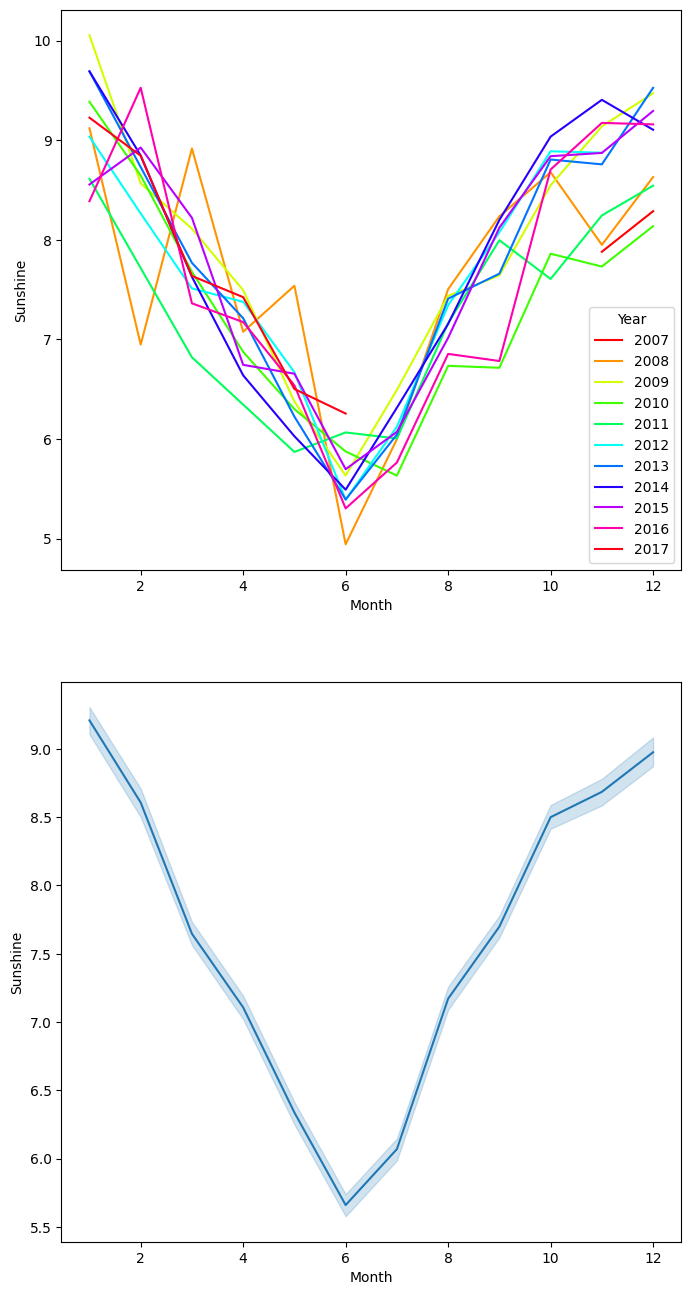

In [51]:
# Lineplot for sunshine.
fig, ax = plt.subplots(2, 1, figsize=(8,16))
x = "Month"
y = "Sunshine"
# Separate years
sns.lineplot(eda_dataset, x=x, y=y, hue="Year", palette="hsv", errorbar=None, legend="full", ax=ax[0])

# All years
sns.lineplot(eda_dataset, x=x, y=y, ax=ax[1])

#### Results
This graph will not only be affected by clouds or rain. Since the criteria for sunshine is based on hours of bright sunshine per day, and Australia does not lie on the equator, the amount of sunlight, and therefore also the Sunshine feature, is affected by the season. This means that for the winter months especially, the sunshine feature is expected to be lower as shown in the graph. Ideally, the model should be able to take the month into account when judging the importance of the Sunshine feature. Other than that clarification, the graph shows little surprises, with the summer months seeing the most sunlight. Additionally, the global minimum of the graph is in June, which is where the winter solstice lies.

[Text(0, 0.5, 'Temperature')]

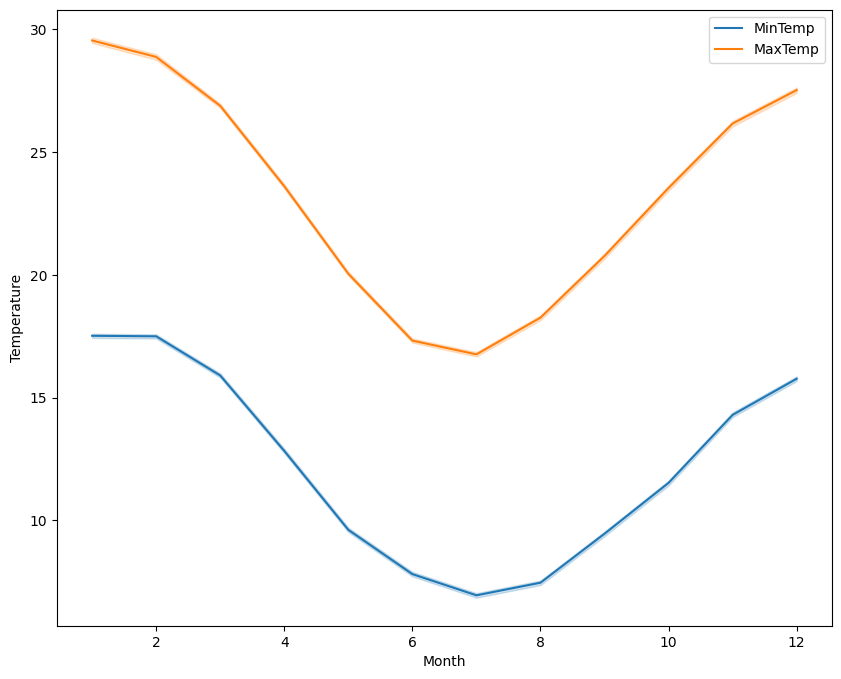

In [52]:
# Lineplot for RainTomorrow (target value).
fig, ax = plt.subplots(1, 1, figsize=(10,8))

x = "Month"
y = "MinTemp"
sns.lineplot(eda_dataset, x=x, y=y, ax=ax, label="MinTemp")


y = "MaxTemp"
sns.lineplot(eda_dataset, x=x, y=y, ax=ax, label="MaxTemp")

# Set common label of y-axes.
ax.set(ylabel = "Temperature")
# Gives the months with the most days with rain a higher position on the graph, rather than lower.
# ax.invert_yaxis()


#### Results
This graph shows that the features MinTemp and MaxTemp are heavily correlated. They both follow seasonal behavior which is also shown. Unsurprisingly it is colder in the winter, and warmer in the summer.